# Discrete Krylov representation of the 3p vertex (`vertex_krylov`), Step 1

This notebook is the complete record of results of Step 1 (phases V0, V1, V2, V3a, V3b) of the `vertex_krylov`
task. It implements and tests Algorithm 2 of the project note **[VD]** *Jacobi matrices and couplings of the 3p
vertex from discrete spectral data*, which takes discrete 2p and 3p PSF weights on one symmetric grid and returns the
Jacobi matrices $\bar{\mathbb J}$, $\bar N$ ($\bar{\mathbb J}_d=-\bar{\mathbb J}^T$), $\mathbb J_B, N_B$,
$\mathbb J_{B^\dagger}, N_{B^\dagger}$, the couplings (VD27) and the self-energy coefficients $\Sigma^{\rm L}$,
$\Sigma^{\rm R}$ (VD4). Inserted into (VD6)–(VD12) they give the Matsubara regular part $\tilde K^{(12)}$ of Lihm's
3p estimator. [VD] Theorem 2 claims exactness for exact Lehmann data at $T>0$ and for binned data with bins
symmetric about zero.

| regime | data source | exactness | section |
|:--|:--|:--|:--|
| Hubbard atom (V1) | HubbardAtom ED, ExactGrid | exact | 2 |
| short Wilson chain (V2a/V2b) | mpNRG ED of the chain, ExactGrid / LogGrid | exact | 3 |
| same chain, untruncated NRG (V3a) | mpNRG NRG, LogGrid | exact | 4 |
| decoupled tail, truncated NRG (V3b) | mpNRG NRG, LogGrid | exact | 5 |

The physical truncated chain (V3c) is Step 2 and not part of this notebook.

**Code.** `src/vertex_krylov.jl` (package `HubbardAtom`, imported as `HA`; depends on `LinearAlgebra` only) and
`mpNRG/test/vertex_krylov_adapter.jl` (data from mpNRG, case runners). The tests
`test/test_vertex_krylov.jl` (V0, V1) and `mpNRG/test/test_vertex_krylov_nrg.jl` (V2, V3a, V3b) assert the same
checks with the same functions.

**Conventions.** $H_{\rm int}=Un_\uparrow n_\downarrow$; $q_\sigma=[d_\sigma,H_{\rm int}]$,
$q^\dagger_\sigma=[H_{\rm int},d^\dagger_\sigma]$, $B=q_{i_1i_2}=\{q_{i_1},d^\dagger_{i_2}\}$ (called `Bq` in code;
`siam(B = …)` is the magnetic field). Channel (↑↓): $(i_1,i_2)=(\downarrow,\downarrow)$, particle chain for
$\sigma=\uparrow$; channel (↑↑): $(i_1,i_2)=(\uparrow,\uparrow)$. Rows $X=(d^\dagger_\sigma,q^\dagger_\sigma)$,
$X_d=(d_\sigma,q_\sigma)$. PSFs follow Kugler Eq. (28), without permutation signs.

In [1]:
using Pkg
Pkg.activate(normpath(joinpath(@__DIR__, "..", "mpNRG", "notebooks")); io = devnull)   # the notebook environment
using MultipointNRG, LinearAlgebra, Printf
import HubbardAtom as HA
using CairoMakie
CairoMakie.activate!(type = "png")
const ROOT = normpath(joinpath(@__DIR__, ".."))
include(joinpath(ROOT, "mpNRG", "test", "helpers.jl"))
include(joinpath(ROOT, "mpNRG", "test", "vertex_krylov_adapter.jl"))
FIG = joinpath(@__DIR__, "figures", "vertex_krylov"); mkpath(FIG)
savefig(name, fig) = (save(joinpath(FIG, name * ".png"), fig; px_per_unit = 2); fig)
fl(x) = max(x, 1e-17)
println("Julia ", VERSION, ", threads ", Threads.nthreads(), ", BLAS threads ", BLAS.get_num_threads())

[ Info: Precompiling HubbardAtom [3f1a6d2e-9c7b-4e85-9a31-5d0c8f4b2a67] (caches not reused: 2 for file size changed)


Precompiling packages...


Julia 1

   2.0 s  ✓ HubbardAtom
  1 dependency successfully precompiled in 5 seconds. 306 already precompiled.


.13.3, threads 4, BLAS threads 2


## Computation of all cases

All cases of the Step-1 test matrix are computed here, once, by the case runners of the adapter
(`vk_run`, `vk_case_ed`, `vk_case_nrg`), which call `HA.vertex_krylov` and `HA.vk_checks`. The sections below only
display and plot these results. Timings per case are printed and collected in `TIMES`.

In [2]:
R = Dict{String,Any}()      # all results, keyed by case label
# VK_NB_SMOKE=1: structural test run of this notebook on the Nch = 1 data only (the Nch = 2 labels then
# point to the Nch = 1 results). The committed notebook is executed without it.
const SMOKE = get(ENV, "VK_NB_SMOKE", "0") == "1"
NCHS = SMOKE ? (1,) : (1, 2)
TIMES = Dict{String,Any}()
tstart = time()

# --- V1: Hubbard atom, U = 1, εd = -0.3 ------------------------------------------------
const U_AT, ED_AT = 1.0, -0.3
function atom_case(T, chan; σ = :up, h = 0.0, i12 = nothing, rot = nothing)
    m = HA.HubbardAtomModel(U_AT, 1 / T)
    sp = HA.atom_spectrum(m; εd = ED_AT, h = h)
    t0 = time()
    d = HA.discrete_data_atom(m, sp; σ = σ, channel = chan, εd = ED_AT, h = h, i12 = i12, rot = rot)
    tm = Dict{Symbol,Float64}(:data => time() - t0)
    out = vk_run(d; bigfloat = d.N == 1, timings = tm)
    out[:data] = d
    d.N == 1 && rot === nothing && (out[:closed] = HA.atom_closed_form(out[:res]))
    return out
end
for T in (0.1, 0.5), chan in (:updn, :upup)
    R["V1 atom T=$T $chan"] = atom_case(T, chan)
end
for h in (0.0, 0.07)
    R["V1 atom N=2 h=$h"] = atom_case(0.1, :updn; σ = [:up, :dn], i12 = (:dn, :dn), h = h)
    R["V1 atom N=1 up h=$h"] = atom_case(0.1, :updn; σ = :up, h = h)
    R["V1 atom N=1 dn h=$h"] = atom_case(0.1, :upup; σ = :dn, h = h)
end
θ, φ = 0.4, 0.9
ROT = [cos(θ) exp(im * φ) * sin(θ); -exp(-im * φ) * sin(θ) cos(θ)]
R["V1 atom N=2 rotated"] = atom_case(0.1, :updn; σ = [:up, :dn], i12 = (1, 1), h = 0.07, rot = ROT)
@printf("V1 done: %.1f s\n", time() - tstart)

# --- V2: Wilson chain, ED (exact and binned) ---------------------------------------------
KEEP = Set(["V2 Nch=2 B=0.0 updn exact", "V2 Nch=2 B=0.0 updn log", "V2 Nch=1 B=0.0 updn exact", "V3a Nch=2 B=0.0 updn"])
SMOKE && (KEEP = union(KEEP, Set(replace.(collect(KEEP), "Nch=2" => "Nch=1"))))
for Nch in NCHS, field in (0.0, 0.05), chan in (:updn, :upup), gk in (:exact, :log)
    t0 = time()
    k = "V2 Nch=$Nch B=$field $chan $gk"
    # BigFloat particle chain only for Nch ≤ 1 (Nch = 2: R ≈ 2600 rows, L ≈ 2600 steps; deviation in STATUS)
    R[k] = vk_case_ed(Nch, gk, chan; field = field, bigfloat = gk === :exact && Nch == 1, keep = k in KEEP)
    GC.gc()
    @printf("V2 Nch=%d B=%.2f %-5s %-5s: %6.1f s\n", Nch, field, chan, gk, time() - t0)
end
t0 = time()
R["V2 block N=2"] = vk_case_ed(1, :exact, :updn; field = 0.05, σ = [:up, :dn], i12 = (:dn, :dn))
R["V2 block up"] = vk_case_ed(1, :exact, :updn; field = 0.05)
R["V2 block dn"] = vk_case_ed(1, :exact, :upup; field = 0.05, σ = :dn)
@printf("V2 block test: %.1f s\n", time() - t0)
# smallest reproducing case of finding F1 (sites -1..0, 16 states)
R["V2 Nch=0 B=0.0 updn exact"] = vk_case_ed(0, :exact, :updn; bigfloat = true)

# --- V3a: untruncated NRG ----------------------------------------------------------------
for Nch in NCHS, field in (0.0, 0.05), chan in (:updn, :upup)
    t0 = time()
    k = "V3a Nch=$Nch B=$field $chan"
    R[k] = vk_case_nrg(Nch, chan; field = field, keep = k in KEEP)
    GC.gc()
    @printf("V3a Nch=%d B=%.2f %-5s: %6.1f s\n", Nch, field, chan, time() - t0)
end

# --- V3b: decoupled tail, truncated NRG ----------------------------------------------------
for chan in (:updn, :upup)
    t0 = time()
    chs = decoupled_tail(wilson_chains(vk_model(), 3), 1)
    R["V3b $chan"] = vk_case_nrg(3, chan; Nkeep = 40, chains = chs)
    @printf("V3b %-5s: %6.1f s\n", chan, time() - t0)
end
if SMOKE
    for k in collect(keys(R))
        occursin("Nch=1", k) && (R[replace(k, "Nch=1" => "Nch=2")] = R[k])
    end
end
println("SMOKE = ", SMOKE)
@printf("all cases: %.1f min\n", (time() - tstart) / 60)

V1 done: 64.3 s
V2 Nch=1 B=0.00 updn  exact:   23.9 s


V2 Nch=1 B=0.00 updn  log  :    2.7 s
V2 Nch=1 B=0.00 upup  exact:   11.9 s


V2 Nch=1 B=0.00 upup  log  :    1.5 s
V2 Nch=1 B=0.05 updn  exact:   24.0 s


V2 Nch=1 B=0.05 updn  log  :    1.9 s
V2 Nch=1 B=0.05 upup  exact:   26.7 s


V2 Nch=1 B=0.05 upup  log  :    1.8 s
V2 Nch=2 B=0.00 updn  exact:  737.4 s


V2 Nch=2 B=0.00 updn  log  :    7.9 s
V2 Nch=2 B=0.00 upup  exact:  731.9 s


... (10 outputs left out)

V3a Nch=2 B=0.05 upup :   14.8 s


V3b updn :    4.7 s


V3b upup :    3.6 s
SMOKE = 

false
all cases: 97.1 min


## 0. Summary

The full Step-1 test matrix (task sheet Sec. 6): phase × case × channel × check, with the achieved value, the
tolerance, and pass / FAIL / report. **Guaranteed** tolerances follow from [VD] Theorem 2 (stop rule); "report" means
measured only. Generated from `R` by the same check functions as the tests.

* C1 self-energy (algebraic), C2 Zacinskis cross-check ($\Sigma^{\rm S}$, spectra and weights of $\Omega'$; report),
  C3 Dyson, C4 bath leakage, C5 hole symmetry, C6 Gauss quadrature, C7 factorization residual, C8 assembly.
* For exact data C4 is listed twice: for the particle chain of Algorithm 2 (projector $1-vv^\dagger$) and for the
  stabilized chain of [VD] Prop. 13 (projector $1-\Omega\Omega^\dagger$).
* C8 is relative to $\max|K^{\rm direct}|$, except where $K^{\rm direct}\equiv0$ (marked `†`, see deviation 4 of
  `vertex_krylov_STATUS.md`).

In [3]:
ROWS = Any[]
function row!(phase, case, chan, check, val, tol; note = "")
    st = tol === nothing ? "report" : isnan(val) ? "n/a" : (val ≤ tol ? "pass" : "FAIL")
    push!(ROWS, (phase = phase, case = case, chan = chan, check = check, value = val, tol = tol, status = st, note = note))
end
TOL = Dict("V1" => (C1 = 1e-11, C34 = 1e-11, C56 = 1e-12, C7 = 1e-11, C8 = 1e-10),
           "V2a" => (C1 = 1e-10, C34 = 1e-9, C56 = 1e-12, C7 = 1e-10, C8 = 1e-9),
           "V2b" => (C1 = 1e-10, C34 = nothing, C56 = 1e-12, C7 = 1e-10, C8 = 1e-9),
           "V3a" => (C1 = 1e-10, C34 = nothing, C56 = 1e-11, C7 = 1e-9, C8 = 1e-8),
           "V3b" => (C1 = 1e-10, C34 = nothing, C56 = 1e-11, C7 = 1e-9, C8 = 1e-8))
function rows_for!(phase, case, chan, out)
    t = TOL[phase]; c = out[:checks]
    row!(phase, case, chan, "C1", c[:C1], t.C1)
    row!(phase, case, chan, "C2", c[:C2], nothing)
    row!(phase, case, chan, "C3", c[:C3], t.C34)
    row!(phase, case, chan, "C4", c[:C4], t.C34)
    haskey(out, :big) && row!(phase, case, chan, "C4 (BigFloat chain)", out[:big].C4, t.C34)
    haskey(out, :stab) && row!(phase, case, chan, "C4 (stabilized)", out[:stab].C4, t.C34)
    row!(phase, case, chan, "C5", c[:C5], t.C56)
    row!(phase, case, chan, "C6", c[:C6], t.C56)
    row!(phase, case, chan, "C7", c[:C7], t.C7)
    row!(phase, case, chan, "C8", c[:C8], t.C8; note = c[:C8_parts].degenerate ? "†" : "")
end
chs(s) = s === :updn ? "(↑↓)" : "(↑↑)"
for T in (0.1, 0.5), chan in (:updn, :upup)
    rows_for!("V1", "atom T=$T", chs(chan), R["V1 atom T=$T $chan"])
    cf = R["V1 atom T=$T $chan"][:closed]
    row!("V1", "atom T=$T", chs(chan), "closed form |ΔJ̄|,|ΔN̄²|,|Δσ|", max(cf.J_err, cf.N2_err, cf.σ_err), 1e-12)
    row!("V1", "atom T=$T", chs(chan), "chain length 1, resid", cf.L == 1 ? cf.resid : Inf, 1e-12)
end
for h in (0.0, 0.07)
    rows_for!("V1", "atom N=2 h=$h", "B=q↓↓", R["V1 atom N=2 h=$h"])
end
rows_for!("V1", "atom N=2 rotated", "B=q′₁₁", R["V1 atom N=2 rotated"])
for Nch in (1, 2), field in (0.0, 0.05), chan in (:updn, :upup)
    case = "chain Nch=$Nch B=$field"
    rows_for!("V2a", case, chs(chan), R["V2 Nch=$Nch B=$field $chan exact"])
end
for Nch in (1, 2), field in (0.0, 0.05), chan in (:updn, :upup)
    rows_for!("V2b", "chain Nch=$Nch B=$field", chs(chan), R["V2 Nch=$Nch B=$field $chan log"])
end
rows_for!("V2a", "N=2 block, Nch=1 B=0.05", "B=q↓↓", R["V2 block N=2"])
for Nch in (1, 2), field in (0.0, 0.05), chan in (:updn, :upup)
    o = R["V3a Nch=$Nch B=$field $chan"]
    rows_for!("V3a", "NRG Nch=$Nch B=$field", chs(chan), o)
    row!("V3a", "NRG Nch=$Nch B=$field", chs(chan), "data vs V2b max|ΔW̃|,|Δs|", max(o[:diff].W, o[:diff].wB, o[:diff].s), nothing)
end
for chan in (:updn, :upup)
    o = R["V3b $chan"]
    rows_for!("V3b", "decoupled tail Nkeep=40", chs(chan), o)
    row!("V3b", "decoupled tail Nkeep=40", chs(chan), "data vs ED max|ΔW̃|,|Δs|", max(o[:diff].W, o[:diff].wB, o[:diff].s), nothing)
end
@printf("%-5s %-26s %-7s %-30s %11s %9s  %s\n", "phase", "case", "channel", "check", "value", "tol", "status")
for r in ROWS
    @printf("%-5s %-26s %-7s %-30s %11.2e %9s  %s%s\n", r.phase, r.case, r.chan, r.check, r.value,
            r.tol === nothing ? "—" : @sprintf("%.0e", r.tol), r.status, r.note)
end
FAILS = filter(r -> r.status == "FAIL", ROWS)
println("\n", length(ROWS), " rows: ", count(r -> r.status == "pass", ROWS), " pass, ", length(FAILS), " FAIL, ",
        count(r -> r.status == "report", ROWS), " report")

phase case                       channel check                                value       tol  status
V1    atom T=0.1                 (↑↓)    C1                                7.98e-16     1e-11  pass


V1    atom T=0.1                 (↑↓)    C2                                2.83e-14         —  report
V1    atom T=0.1                 (↑↓)    C3                                1.68e-15     1e-11  pass
V1    atom T=0.1                 (↑↓)    C4                                2.22e-16     1e-11  pass
V1    atom T=0.1                 (↑↓)    C4 (BigFloat chain)               1.46e-16     1e-11  pass
V1    atom T=0.1                 (↑↓)    C4 (stabilized)                   2.22e-16     1e-11  pass
V1    atom T=0.1                 (↑↓)    C5                                0.00e+00     1e-12  pass
V1    atom T=0.1                 (↑↓)    C6                                1.05e-16     1e-12  pass
V1    atom T=0.1                 (↑↓)    C7                                3.42e-16     1e-11  pass
V1    atom T=0.1                 (↑↓)    C8                                3.83e-16     1e-10  pass
V1    atom T=0.1                 (↑↓)    closed form |ΔJ̄|,|ΔN̄²|,|Δσ|       8.33e-17     1e-12  p

V2a   chain Nch=1 B=0.05         (↑↓)    C4 (BigFloat chain)               5.56e-01     1e-09  FAIL
V2a   chain Nch=1 B=0.05         (↑↓)    C4 (stabilized)                   4.99e-16     1e-09  pass
V2a   chain Nch=1 B=0.05         (↑↓)    C5                                0.00e+00     1e-12  pass
V2a   chain Nch=1 B=0.05         (↑↓)    C6                                1.22e-15     1e-12  pass
V2a   chain Nch=1 B=0.05         (↑↓)    C7                                8.72e-16     1e-10  pass
V2a   chain Nch=1 B=0.05         (↑↓)    C8                                3.10e-15     1e-09  pass
V2a   chain Nch=1 B=0.05         (↑↑)    C1                                1.35e-15     1e-10  pass
V2a   chain Nch=1 B=0.05         (↑↑)    C2                                1.51e-13         —  report
V2a   chain Nch=1 B=0.05         (↑↑)    C3                                6.54e-14     1e-09  pass
V2a   chain Nch=1 B=0.05         (↑↑)    C4                                5.50e-01     1e-09  FAI

V2b   chain Nch=2 B=0.0          (↑↑)    C7                                6.20e-16     1e-10  pass
V2b   chain Nch=2 B=0.0          (↑↑)    C8                                4.22e-14     1e-09  pass
V2b   chain Nch=2 B=0.05         (↑↓)    C1                                2.05e-15     1e-10  pass
V2b   chain Nch=2 B=0.05         (↑↓)    C2                                3.83e-14         —  report
V2b   chain Nch=2 B=0.05         (↑↓)    C3                                3.63e-01         —  report
V2b   chain Nch=2 B=0.05         (↑↓)    C4                                3.38e-01         —  report
V2b   chain Nch=2 B=0.05         (↑↓)    C5                                0.00e+00     1e-12  pass
V2b   chain Nch=2 B=0.05         (↑↓)    C6                                7.16e-16     1e-12  pass
V2b   chain Nch=2 B=0.05         (↑↓)    C7                                8.11e-16     1e-10  pass
V2b   chain Nch=2 B=0.05         (↑↓)    C8                                2.72e-14     1e-09 

V3a   NRG Nch=2 B=0.05           (↑↑)    data vs V2b max|ΔW̃|,|Δs|          5.30e-15         —  report
V3b   decoupled tail Nkeep=40    (↑↓)    C1                                1.23e-15     1e-10  pass
V3b   decoupled tail Nkeep=40    (↑↓)    C2                                7.12e-14         —  report
V3b   decoupled tail Nkeep=40    (↑↓)    C3                                2.03e-01         —  report
V3b   decoupled tail Nkeep=40    (↑↓)    C4                                3.72e-01         —  report
V3b   decoupled tail Nkeep=40    (↑↓)    C5                                0.00e+00     1e-11  pass
V3b   decoupled tail Nkeep=40    (↑↓)    C6                                3.74e-16     1e-11  pass
V3b   decoupled tail Nkeep=40    (↑↓)    C7                                4.89e-16     1e-09  pass
V3b   decoupled tail Nkeep=40    (↑↓)    C8                                3.36e-15     1e-08  pass
V3b   decoupled tail Nkeep=40    (↑↓)    data vs ED max|ΔW̃|,|Δs|           3.22e-15       

314 rows: 221 pass, 13 FAIL, 80 report


### Failures and open findings

Generated list of all FAIL rows, followed by the findings of Sec. 7.

In [4]:
if isempty(FAILS)
    println("Failures: none")
else
    println("Failures (guaranteed check beyond tolerance):")
    for r in FAILS
        @printf("  %-5s %-26s %-7s %-18s %.2e > %.0e\n", r.phase, r.case, r.chan, r.check, r.value, r.tol)
    end
    fc = unique([r.check for r in FAILS])
    println("checks affected: ", join(fc, ", "))
end
println("\nOpen findings: F1 (C4 without stabilization, see Sec. 7); F2 (C2 Jacobi blocks agree only on leading blocks);",
        " F3 (K ≡ 0 in the atom's (↑↑) channel).")

Failures (guaranteed check beyond tolerance):
  V2a   chain Nch=1 B=0.0          (↑↓)    C4                 8.45e-01 > 1e-09
  V2a   chain Nch=1 B=0.0          (↑↓)    C4 (BigFloat chain) 8.35e-01 > 1e-09


  V2a   chain Nch=1 B=0.0          (↑↑)    C4                 8.30e-01 > 1e-09
  V2a   chain Nch=1 B=0.0          (↑↑)    C4 (BigFloat chain) 8.14e-01 > 1e-09
  V2a   chain Nch=1 B=0.05         (↑↓)    C4                 4.74e-01 > 1e-09
  V2a   chain Nch=1 B=0.05         (↑↓)    C4 (BigFloat chain) 5.56e-01 > 1e-09
  V2a   chain Nch=1 B=0.05         (↑↑)    C4                 5.50e-01 > 1e-09
  V2a   chain Nch=1 B=0.05         (↑↑)    C4 (BigFloat chain) 5.55e-01 > 1e-09
  V2a   chain Nch=2 B=0.0          (↑↓)    C4                 2.48e-01 > 1e-09
  V2a   chain Nch=2 B=0.0          (↑↑)    C4                 2.36e-01 > 1e-09
  V2a   chain Nch=2 B=0.05         (↑↓)    C4                 1.99e-01 > 1e-09
  V2a   chain Nch=2 B=0.05         (↑↑)    C4                 2.01e-01 > 1e-09
  V2a   N=2 block, Nch=1 B=0.05    B=q↓↓   C4                 6.44e-01 > 1e-09
checks affected: C4, C4 (BigFloat chain)

Open findings: F1 (C4 without stabilization, see Sec. 7); F2 (C2 Jacobi blocks agree o

## 1. Conventions

Checked before any comparison is trusted (task sheet Secs. 2.2, 2.3, 2.5, 5.1):

1. PSF convention (Kugler Eq. (28)) on a 2p example by explicit Lehmann summation: expected agreement to rounding.
2. ζ signs of $(p_1,\dots,p_6)$ for $(q_{12},T^{(3)},T^{(4)})$ from `HA.permutation_sign(p, [false,true,true])`:
   expected $(+,-,+,-,-,+)$.
3. Odd bin map, $c(-E)=-c(E)$, for the ExactGrid and the LogGrid.
4. The (I3) index map with the barred indices, with one worked entry.
5. The frequency convention of `regular_sum`: `z = [iω12, iω3, iω4]` must equal the [3p] Sec. III.3 form
   $\sum_p\zeta^pF_p[\vec{\mathcal O}_p](i\alpha_{\bar1},-i\alpha_{\bar3})$, evaluated independently with the
   Liouvillian superoperator in the eigenbasis (`HA.liouvillian_regular`).

In [5]:
m = HA.HubbardAtomModel(U_AT, 10.0); sp = HA.atom_spectrum(m; εd = ED_AT)
ops = HA.vk_atom_operators(m; spins = [:up], i12 = (:dn, :dn))
@printf("1. PSF convention: max |Δw| = %.1e (S[d,d†]), %.1e (S[q,d†]), %.1e (S[B†,B])\n",
        HA.psf_convention_check(sp, ops.Xd[1], ops.X[1]), HA.psf_convention_check(sp, ops.Xd[2], ops.X[1]),
        HA.psf_convention_check(sp, ops.Bqd, ops.Bq))
println("2. ζ(p1..p6) = ", HA.vk_zeta(), "   expected [1, -1, 1, -1, -1, 1]: ", HA.vk_zeta() == [1, -1, 1, -1, -1, 1])
ge = R["V2 Nch=1 B=0.0 updn exact"][:data].meta[:grid]
bg, _ = vk_loggrid(vk_grid())
xs = vcat(10.0 .^ range(-7, 1.5; length = 400), [0.0, 1e-15, 3e-14])
println("3. odd bin map: LogGrid ", all(x -> HA.bin_of(bg, -x) == bg.bar[HA.bin_of(bg, x)], xs),
        "; ExactGrid (V2a Nch=1, ", length(ge.b), " bins) ", all(β -> HA.bin_of(ge, -ge.b[β]) == ge.bar[β], eachindex(ge.b)),
        "; within-cluster spread ", @sprintf("%.1e", ge.spread))

1. PSF convention: max |Δw| = 0.0e+00 (S[d,d†]), 0.0e+00 (S[q,d†]), 0.0e+00 (S[B†,B])
2. ζ(p1..p6) = 

[1, -1, 1, -1, -1, 1]   expected [1, -1, 1, -1, -1, 1]: true
3. odd bin map: LogGrid 

true; ExactGrid (V2a Nch=1, 625 bins) true; within-cluster spread 2.6e-15


In [6]:
# 4. (I3) worked entry: s2[α,β][a,b] = S(ᾱ, β̄)[X_a, B, X_b†] for the atom, channel (↑↑) (B = q↑↑), T = 0.1
#    (in the (↑↓) channel of the atom the family s2 vanishes identically)
d = R["V1 atom T=0.1 upup"][:data]
ops = HA.vk_atom_operators(m; spins = [:up], i12 = (:up, :up))
println("(I3): s1 = S(α,β)[X_a†,B,X_b], s2 = S(ᾱ,β̄)[X_a,B,X_b†], s3 = S(α,β)[B,x,X_b], s4 = S(ᾱ,β)[X_a,x,B],")
println("      s5 = S(α,β̄)[B,y,X_b†], s6 = S(α,β)[X_a†,y,B]")
(k, blk) = first(sort(collect(d.s2); by = first))
a, b = Tuple(argmax(abs.(blk)))
α, β = k
names = ["d†", "q†"]
@printf("worked entry: s2[(α,β) = (%d,%d)][a,b] = [%s,%s] = %.6f, i.e. the PSF S[%s, B, %s] at (ε1,ε2) = (b_ᾱ, b_β̄) = (%.4f, %.4f)\n",
        α, β, names[a], names[b], real(blk[a, b]), names[a], names[b] == "d†" ? "d" : "q", d.b[d.bar[α]], d.b[d.bar[β]])
ts = HA.psf(sp, (ops.X[a], ops.Bq, ops.Xd[b]))
w = sum(t.weight for t in ts if abs(t.position[1] - d.b[d.bar[α]]) < 1e-10 && abs(t.position[2] - d.b[d.bar[β]]) < 1e-10; init = 0.0im)
@printf("direct PSF sum at that position: %.6f  (difference %.1e)\n", real(w), abs(w - blk[a, b]))

(I3): s1 = S(α,β)[X_a†,B,X_b], s2 = S(ᾱ,β̄)[X_a,B,X_b†], s3 = S(α,β)[B,x,X_b], s4 = S(ᾱ,β)[X_a,x,B],
      s5 = S(α,β̄)[B,y,X_b†], s6 = S(α,β)[X_a†,y,B]
worked entry: s2[(α,β) = (5,5)][a,b] = [d†,d†] = 0.000445, i.e. the PSF S[d†, B, d] at (ε1,ε2) = (b_ᾱ, b_β̄) = (-0.7000, -0.7000)
direct PSF sum at that position: 0.000445  (difference 0.0e+00)


In [7]:
# 5. regular_sum frequency convention vs [3p] Sec. III.3 (Liouvillian form)
err = 0.0
for (n3, n4) in ((0, 0), (2, -5), (-3, 1), (4, 4)), (x, y) in ((ops.q[1], ops.X[2]), (ops.d[1], ops.X[1]), (ops.q[1], ops.X[1]))
    ω3 = HA.vk_fermionic(n3, 0.1); ω4 = HA.vk_fermionic(n4, 0.1); ω12 = -ω3 - ω4
    rs = HA.regular_sum(sp, (ops.Bq, x, y), ComplexF64[im * ω12, im * ω3, im * ω4]; is_fermionic = [false, true, true])
    global err = max(err, abs(rs - HA.liouvillian_regular(sp, (ops.Bq, x, y), [ω12, ω3, ω4])))
end
@printf("5. regular_sum(z = [iω12, iω3, iω4]) vs Σ_p ζ^p F_p(iα_p̄1, -iα_p̄3): max |Δ| = %.1e over 12 points\n", err)

5. regular_sum(z = [iω12, iω3, iω4]) vs Σ_p ζ^p F_p(iα_p̄1, -iα_p̄3): max |Δ| = 6.9e-17 over 12 points


## 2. Hubbard atom (V1)

$U=1$, $\varepsilon_d=-0.3$, $T\in\{0.1,0.5\}$, HubbardAtom ED on the ExactGrid. Expected: the closed-form one-level
chain of [VD] App. F, $\bar{\mathbb J}=\varepsilon_\sigma+U(1-n)$, $\bar N^2=U^2n(1-n)$, $\sigma=Un$,
$n=\langle n_{\bar\sigma}\rangle$, chain length 1; all checks to the V1 tolerances. The bosonic legs of the atom are
trivial ($B$ is a conserved density, $\mathbb J_B$ is $1\times1$ with entry 0). In the (↑↑) channel
$B=Un_\downarrow$ commutes with $H$, $d_\uparrow$, $q_\uparrow$, so $K^{(12)}\equiv0$ at $\omega_{12}\neq0$ while
the six permutation terms are $O(1)$; C8 is then measured on the scale of the permutation terms (also shown: the
per-permutation agreement, which holds term by term).

In [8]:
@printf("%-26s %3s %10s %10s %10s %10s %9s %9s %9s %9s %9s %9s %9s %9s\n", "case", "L", "J̄", "J̄ closed", "N̄²", "N̄² closed",
        "C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8")
for T in (0.1, 0.5), chan in (:updn, :upup)
    o = R["V1 atom T=$T $chan"]; c = o[:checks]; cf = o[:closed]; ch = o[:res].ch
    @printf("%-26s %3d %10.6f %10.6f %10.6f %10.6f %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e %9.1e%s\n", "T=$T $(chs(chan))",
            cf.L, real(ch.Jbar.eps[1][1]), cf.J, real(ch.Nbar[1])^2, cf.N2, c[:C1], c[:C2], c[:C3], c[:C4], c[:C5], c[:C6],
            c[:C7], c[:C8], c[:C8_parts].degenerate ? " †" : "")
end
println("\nC8 detail (abs = max|K̃ - K^direct|, perm = per-permutation error / max|K_p|):")
for T in (0.1, 0.5), chan in (:updn, :upup)
    p = R["V1 atom T=$T $chan"][:checks][:C8_parts]
    @printf("  T=%-4s %s: max|K^direct| = %.2e, max|K_p| = %.2e, abs = %.1e, rel = %.1e, rel_perm = %.1e, perm = %.1e\n",
            T, chs(chan), p.maxKd, p.maxKp, p.abs, p.rel, p.rel_perm, p.perm)
end
println("\nBigFloat (128 bit) particle chain vs Float64: ",
        join([@sprintf("T=%s %s: |ΔJ̄| = %.1e", T, chs(ch), maximum(R["V1 atom T=$T $ch"][:big].dev)) for T in (0.1, 0.5), ch in (:updn, :upup)], "; "))

case                         L          J̄   J̄ closed         N̄²  N̄² closed        C1        C2        C3        C4        C5        C6        C7        C8
T=0.1 (↑↓)                   1   0.211917   0.211917   0.249858   0.249858   8.0e-16   2.8e-14   1.7e-15   2.2e-16   0.0e+00   1.0e-16   3.4e-16   3.8e-16


T=0.1 (↑↑)                   1   0.211917   0.211917   0.249858   0.249858   8.0e-16   2.8e-14   1.7e-15   2.2e-16   0.0e+00   1.0e-16   3.7e-16   3.2e-16 †
T=0.5 (↑↓)                   1   0.254056   0.254056   0.247078   0.247078   5.5e-16   5.4e-15   5.7e-15   1.1e-16   0.0e+00   1.1e-16   1.6e-16   1.5e-16
T=0.5 (↑↑)                   1   0.254056   0.254056   0.247078   0.247078   5.5e-16   5.4e-15   5.7e-15   1.1e-16   0.0e+00   1.1e-16   1.6e-16   1.5e-16 †

C8 detail (abs = max|K̃ - K^direct|, perm = per-permutation error / max|K_p|):
  T=0.1  (↑↓): max|K^direct| = 1.74e+00, max|K_p| = 9.30e-01, abs = 6.7e-16, rel = 3.8e-16, rel_perm = 7.2e-16, perm = 3.7e-16


  T=0.1  (↑↑): max|K^direct| = 1.79e-16, max|K_p| = 1.09e+00, abs = 3.4e-16, rel = 1.9e+00, rel_perm = 3.2e-16, perm = 2.9e-16
  T=0.5  (↑↓): max|K^direct| = 9.76e-02, max|K_p| = 5.88e-02, abs = 1.4e-17, rel = 1.5e-16, rel_perm = 2.4e-16, perm = 1.2e-16
  T=0.5  (↑↑): max|K^direct| = 3.74e-18, max|K_p| = 4.34e-02, abs = 6.3e-18, rel = 1.7e+00, rel_perm = 1.5e-16, perm = 2.5e-16

BigFloat (128 bit) particle chain vs Float64: 

T=0.1 (↑↓): |ΔJ̄| = 8.2e-17; T=0.5 (↑↓): |ΔJ̄| = 2.7e-17; T=0.1 (↑↑): |ΔJ̄| = 8.2e-17; T=0.5 (↑↑): |ΔJ̄| = 2.7e-17


In [9]:
# N = 2 block test: spin-unresolved atom, X = (d†↑, d†↓, q†↑, q†↓), B = q↓↓, vs the N = 1 runs
for h in (0.0, 0.07)
    o2 = R["V1 atom N=2 h=$h"]; ou = R["V1 atom N=1 up h=$h"]; od = R["V1 atom N=1 dn h=$h"]
    b2 = o2[:checks][:box]; bu = ou[:checks][:box]; bd = od[:checks][:box]
    m_ = .!isnan.(real.(bu.Kd))
    zs = HA.vk_testpoints(o2[:data])
    dΣ = maximum(z -> maximum(abs, HA.sigma_chain(o2[:res].ch, z) - Diagonal([HA.sigma_chain(ou[:res].ch, z)[1], HA.sigma_chain(od[:res].ch, z)[1]])), zs)
    @printf("h = %.2f: max|K̃↑↑(N=2) - K̃(N=1,↑)| = %.1e, max|K̃↓↓(N=2) - K̃(N=1,↓)| = %.1e, max|K̃ off-diag| = %.1e, max|ΔΣ^S| = %.1e; C1..C8: %s\n",
            h, maximum(abs, b2.Kt[1, 1, :, :][m_] - bu.Kt[m_]), maximum(abs, b2.Kt[2, 2, :, :][m_] - bd.Kt[m_]),
            max(maximum(abs, b2.Kt[1, 2, :, :][m_]), maximum(abs, b2.Kt[2, 1, :, :][m_])), dΣ,
            join([@sprintf("%.0e", o2[:checks][k]) for k in (:C1, :C2, :C3, :C4, :C5, :C6, :C7, :C8)], " "))
end
o = R["V1 atom N=2 rotated"]; bx = o[:checks][:box]; m_ = .!isnan.(real.(bx.Kd[1, 1, :, :]))
@printf("rotated complex orbitals (h = 0.07): max|K12 - K21| = %.2f (asymmetric, exercises the p2 transposition); C8 = %.1e, C1 = %.1e, C7 = %.1e\n",
        maximum(abs, bx.Kd[1, 2, :, :][m_] - bx.Kd[2, 1, :, :][m_]), o[:checks][:C8], o[:checks][:C1], o[:checks][:C7])

h = 0.00: max|K̃↑↑(N=2) - K̃(N=1,↑)| = 4.0e-16, max|K̃↓↓(N=2) - K̃(N=1,↓)| = 1.7e-16, max|K̃ off-diag| = 0.0e+00, max|ΔΣ^S| = 4.5e-15; C1..C8: 9e-16 2e-14 2e-15 0e+00 0e+00 1e-16 7e-16 2e-16
h = 0.07: max|K̃↑↑(N=2) - K̃(N=1,↑)| = 4.5e-16, max|K̃↓↓(N=2) - K̃(N=1,↓)| = 7.1e-16, max|K̃ off-diag| = 0.0e+00, max|ΔΣ^S| = 1.7e-15; C1..C8: 2e-15 3e-14 2e-15 3e-16 0e+00 2e-16 5e-16 8e-16


rotated complex orbitals (h = 0.07): max|K12 - K21| = 0.36 (asymmetric, exercises the p2 transposition); C8 = 4.6e-16, C1 = 1.1e-15, C7 = 8.0e-16


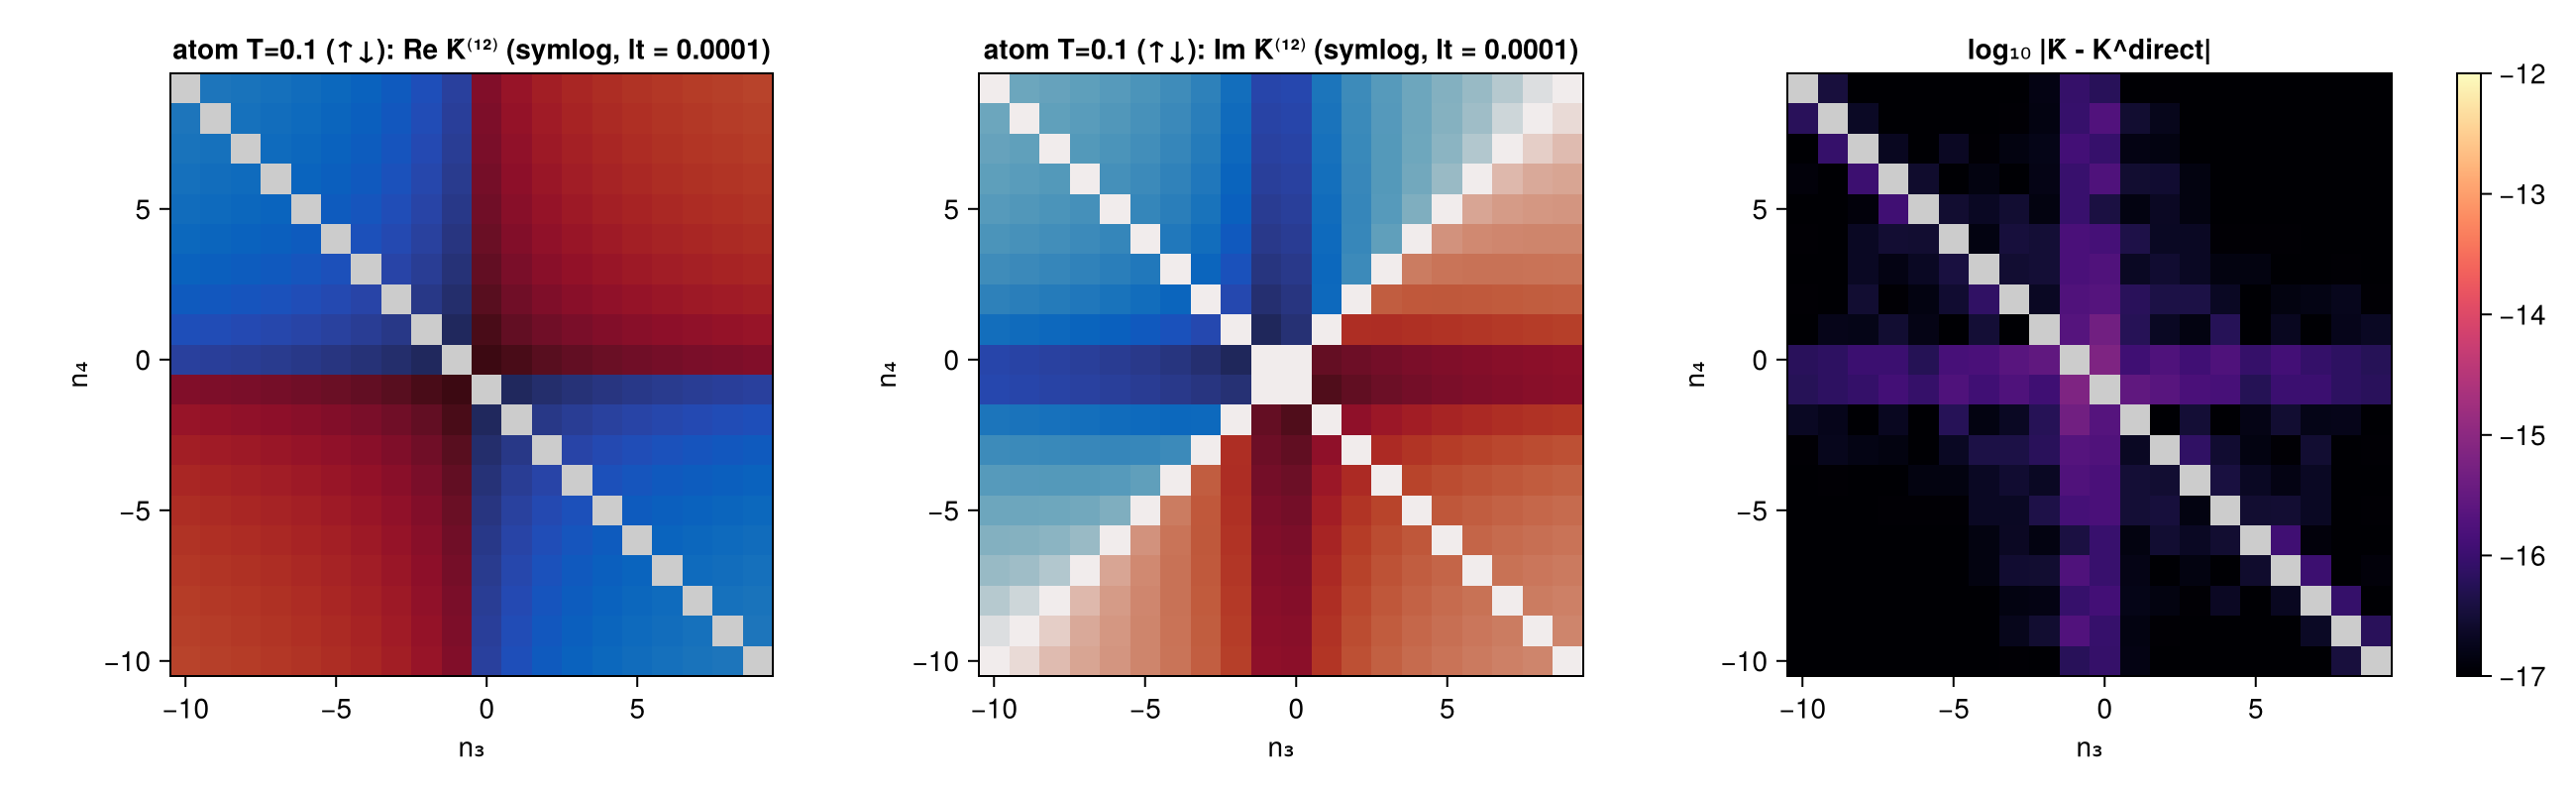

In [10]:
function symlog_heat!(ax, n3s, n4s, M; lt = 1e-4)
    heatmap!(ax, n3s, n4s, map(x -> isnan(x) ? NaN : HA.symlog(x, lt), M); colormap = :balance, colorrange = (-1, 1), nan_color = :gray80)
end
function K_heatmaps(box; title = "", lt = 1e-4)
    fig = Figure(size = (1300, 400))
    for (j, (M, ttl)) in enumerate(((real.(box.Kt), "Re K̃⁽¹²⁾"), (imag.(box.Kt), "Im K̃⁽¹²⁾")))
        ax = Axis(fig[1, j]; xlabel = "n₃", ylabel = "n₄", title = "$title: $ttl (symlog, lt = $lt)", aspect = 1)
        symlog_heat!(ax, box.n3s, box.n4s, M; lt = lt)
    end
    E = abs.(box.Kt - box.Kd)
    ax = Axis(fig[1, 3]; xlabel = "n₃", ylabel = "n₄", title = "log₁₀ |K̃ - K^direct|", aspect = 1)
    hm = heatmap!(ax, box.n3s, box.n4s, log10.(fl.(E)); colormap = :magma, colorrange = (-17, -12), nan_color = :gray80)
    Colorbar(fig[1, 4], hm)
    fig
end
savefig("atom_K_updn", K_heatmaps(R["V1 atom T=0.1 updn"][:checks][:box]; title = "atom T=0.1 (↑↓)"))

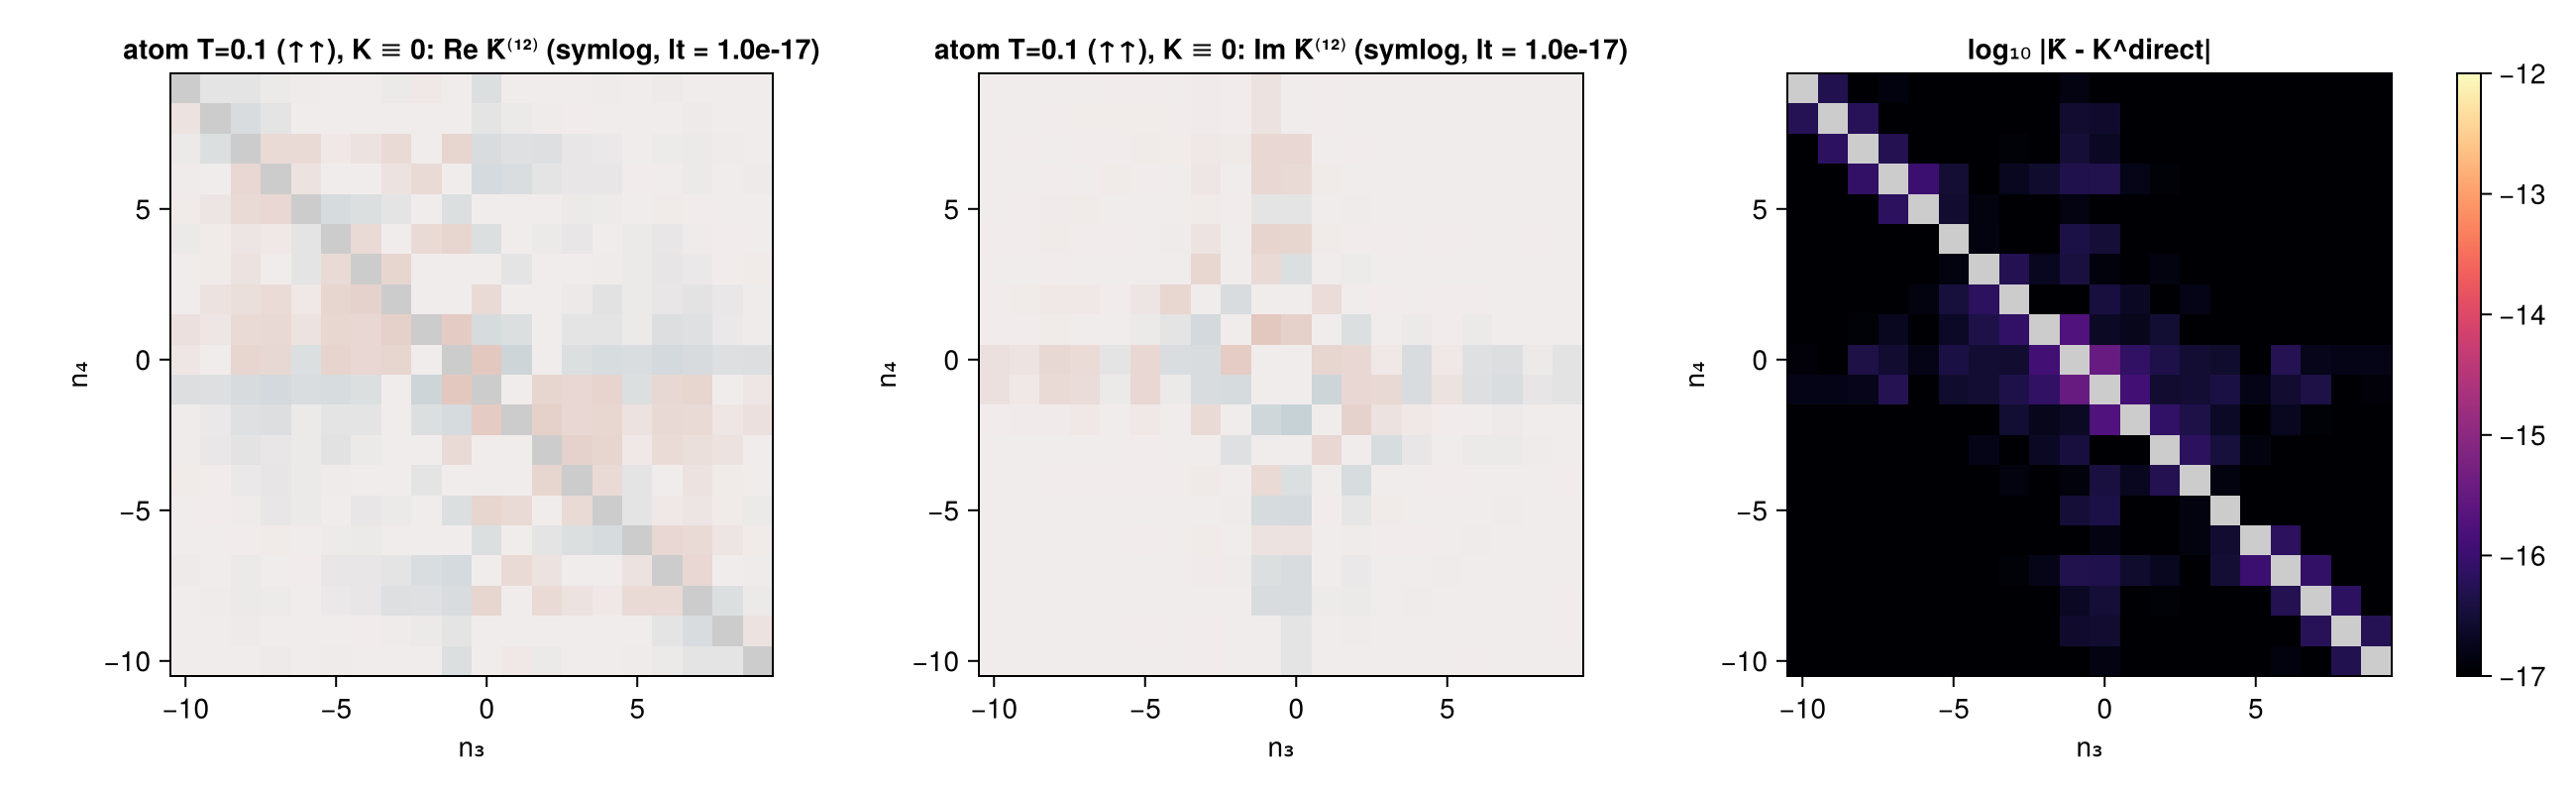

In [11]:
savefig("atom_K_upup", K_heatmaps(R["V1 atom T=0.1 upup"][:checks][:box]; title = "atom T=0.1 (↑↑), K ≡ 0", lt = 1e-17))

## 3. Wilson-chain ED (V2a, V2b)

`siam(U = 0.5, εd = -0.1, Δ = 0.1)`, chains with sites $-1..N_{\rm ch}$, $N_{\rm ch}\in\{1,2\}$ (64 and 256 states),
$T=0.05$, with and without field $B=0.05$, both channels. **V2a**: exact positions on an ExactGrid (`degtol = 1e-10`).
**V2b**: the same ED binned on `LogGrid(emin = 1e-5, emax = 10, ndec = 16)`. Expected (Theorem 2): C1, C5–C8
guaranteed for both; C3 (Dyson) and C4 (bath leakage) guaranteed only for exact data (they use the equation of motion,
which binned data violate by the bin width).

In [12]:
function chain_table(keys)
    @printf("%-34s %6s %5s %4s %4s %9s %9s %9s %9s %9s %9s %9s %9s %9s %9s\n", "case", "bins", "R", "L", "L_B", "C1", "C2", "C3", "C4",
            "C4 stab", "C5", "C6", "C7", "C8", "t [s]")
    for k in keys
        o = R[k]; c = o[:checks]
        @printf("%-34s %6d %5d %4d %4d %9.1e %9.1e %9.1e %9.1e %9s %9.1e %9.1e %9.1e %9.1e %9.1f\n", k, c[:nbins], c[:R], c[:L], c[:LB],
                c[:C1], c[:C2], c[:C3], c[:C4], haskey(o, :stab) ? @sprintf("%.1e", o[:stab].C4) : "—", c[:C5], c[:C6], c[:C7], c[:C8],
                sum(values(o[:timings])))
    end
end
println("V2a (ExactGrid):"); chain_table(["V2 Nch=$N B=$f $c exact" for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)])
println("\nV2b (LogGrid):");  chain_table(["V2 Nch=$N B=$f $c log" for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)])
println("\nsanity (Sec. 3.3), max over V2 cases: ")
for gk in (:exact, :log)
    S = [R["V2 Nch=$N B=$f $c $gk"][:checks][:sanity] for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)]
    @printf("  %-5s herm %.1e, min eig/max‖W‖ %.1e, sum rule %.1e, 3p totals %.1e, C5 %.1e, Boltzmann-shortcut diff %.1e\n", gk,
            maximum(s.herm_err for s in S), minimum(s.min_eig_rel for s in S), maximum(s.sumrule_err for s in S),
            maximum(s.totals3_err for s in S), maximum(s.C5 for s in S), maximum(s.boltzmann_diff for s in S))
end
println("clamped positions on the LogGrid: ", sum(R["V2 Nch=$N B=$f $c log"][:data].meta[:nclamped] for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)))

V2a (ExactGrid):
case                                 bins     R    L  L_B        C1        C2        C3        C4   C4 stab        C5        C6        C7        C8     t [s]
V2 Nch=1 B=0.0 updn exact             625   207  205  217   2.0e-15   1.2e-13   4.4e-14   8.4e-01   1.2e-14   0.0e+00   7.5e-16   9.8e-16   6.3e-15      15.5


V2 Nch=1 B=0.0 upup exact             625   207  205  217   1.8e-15   1.1e-13   4.5e-14   8.3e-01   1.2e-14   0.0e+00   7.7e-16   8.1e-16   4.2e-14      11.6
V2 Nch=1 B=0.05 updn exact            871   282  281  307   2.4e-15   1.5e-13   6.5e-14   4.7e-01   5.0e-16   0.0e+00   1.2e-15   8.7e-16   3.1e-15      23.6
V2 Nch=1 B=0.05 upup exact            871   282  281  307   1.4e-15   1.5e-13   6.5e-14   5.5e-01   5.0e-16   0.0e+00   9.7e-16   8.4e-16   2.2e-14      26.4
V2 Nch=2 B=0.0 updn exact            7901  2616 2615 2797   4.2e-15   1.6e-13   1.0e-13   2.5e-01   4.9e-15   0.0e+00   2.7e-15   9.7e-16   4.8e-14     736.8
V2 Nch=2 B=0.0 upup exact            7901  2616 2615 2797   4.4e-15   1.2e-12   1.0e-13   2.4e-01   4.9e-15   0.0e+00   2.4e-15   5.0e-16   2.8e-13     731.2
V2 Nch=2 B=0.05 updn exact          12163  3840 3839 4483   6.9e-15   2.4e-13   1.6e-13   2.0e-01   5.6e-15   0.0e+00   5.4e-15   5.6e-16   8.4e-14    2119.5
V2 Nch=2 B=0.05 upup exact          12163  3840 3839

clamped positions on the LogGrid: 0

In [13]:
# N = 2 block test on the chain with field B = 0.05 (Nch = 1, ExactGrid)
o2 = R["V2 block N=2"]; ou = R["V2 block up"]; od = R["V2 block dn"]
b2 = o2[:checks][:box]; bu = ou[:checks][:box]; bd = od[:checks][:box]
m_ = .!isnan.(real.(bu.Kd))
zs = HA.vk_testpoints(o2[:data])
dΣ = maximum(z -> maximum(abs, HA.sigma_chain(o2[:res].ch, z) - Diagonal([HA.sigma_chain(ou[:res].ch, z)[1], HA.sigma_chain(od[:res].ch, z)[1]])), zs)
@printf("chain N=2 block (field 0.05): |ΔK̃↑↑| = %.1e, |ΔK̃↓↓| = %.1e, |K̃ off| = %.1e, |ΔΣ^S| = %.1e; L(N=2) = %d blocks, L(↑) = %d, L(↓) = %d\n",
        maximum(abs, b2.Kt[1, 1, :, :][m_] - bu.Kt[m_]), maximum(abs, b2.Kt[2, 2, :, :][m_] - bd.Kt[m_]),
        max(maximum(abs, b2.Kt[1, 2, :, :][m_]), maximum(abs, b2.Kt[2, 1, :, :][m_])), dΣ,
        o2[:checks][:L], ou[:checks][:L], od[:checks][:L])
println("spin blocks differ with field: |K̃↑↑ - K̃↓↓| = ", @sprintf("%.2e", maximum(abs, bu.Kt[m_] - bd.Kt[m_])))

chain N=2 block (field 0.05): |ΔK̃↑↑| = 1.2e-16, |ΔK̃↓↓| = 3.0e-16, |K̃ off| = 1.2e-16, |ΔΣ^S| = 3.2e-16; L(N=2) = 281 blocks, L(↑) = 281, L(↓) = 281
spin blocks differ with field: |K̃↑↑ - K̃↓↓| = 

2.36e-01


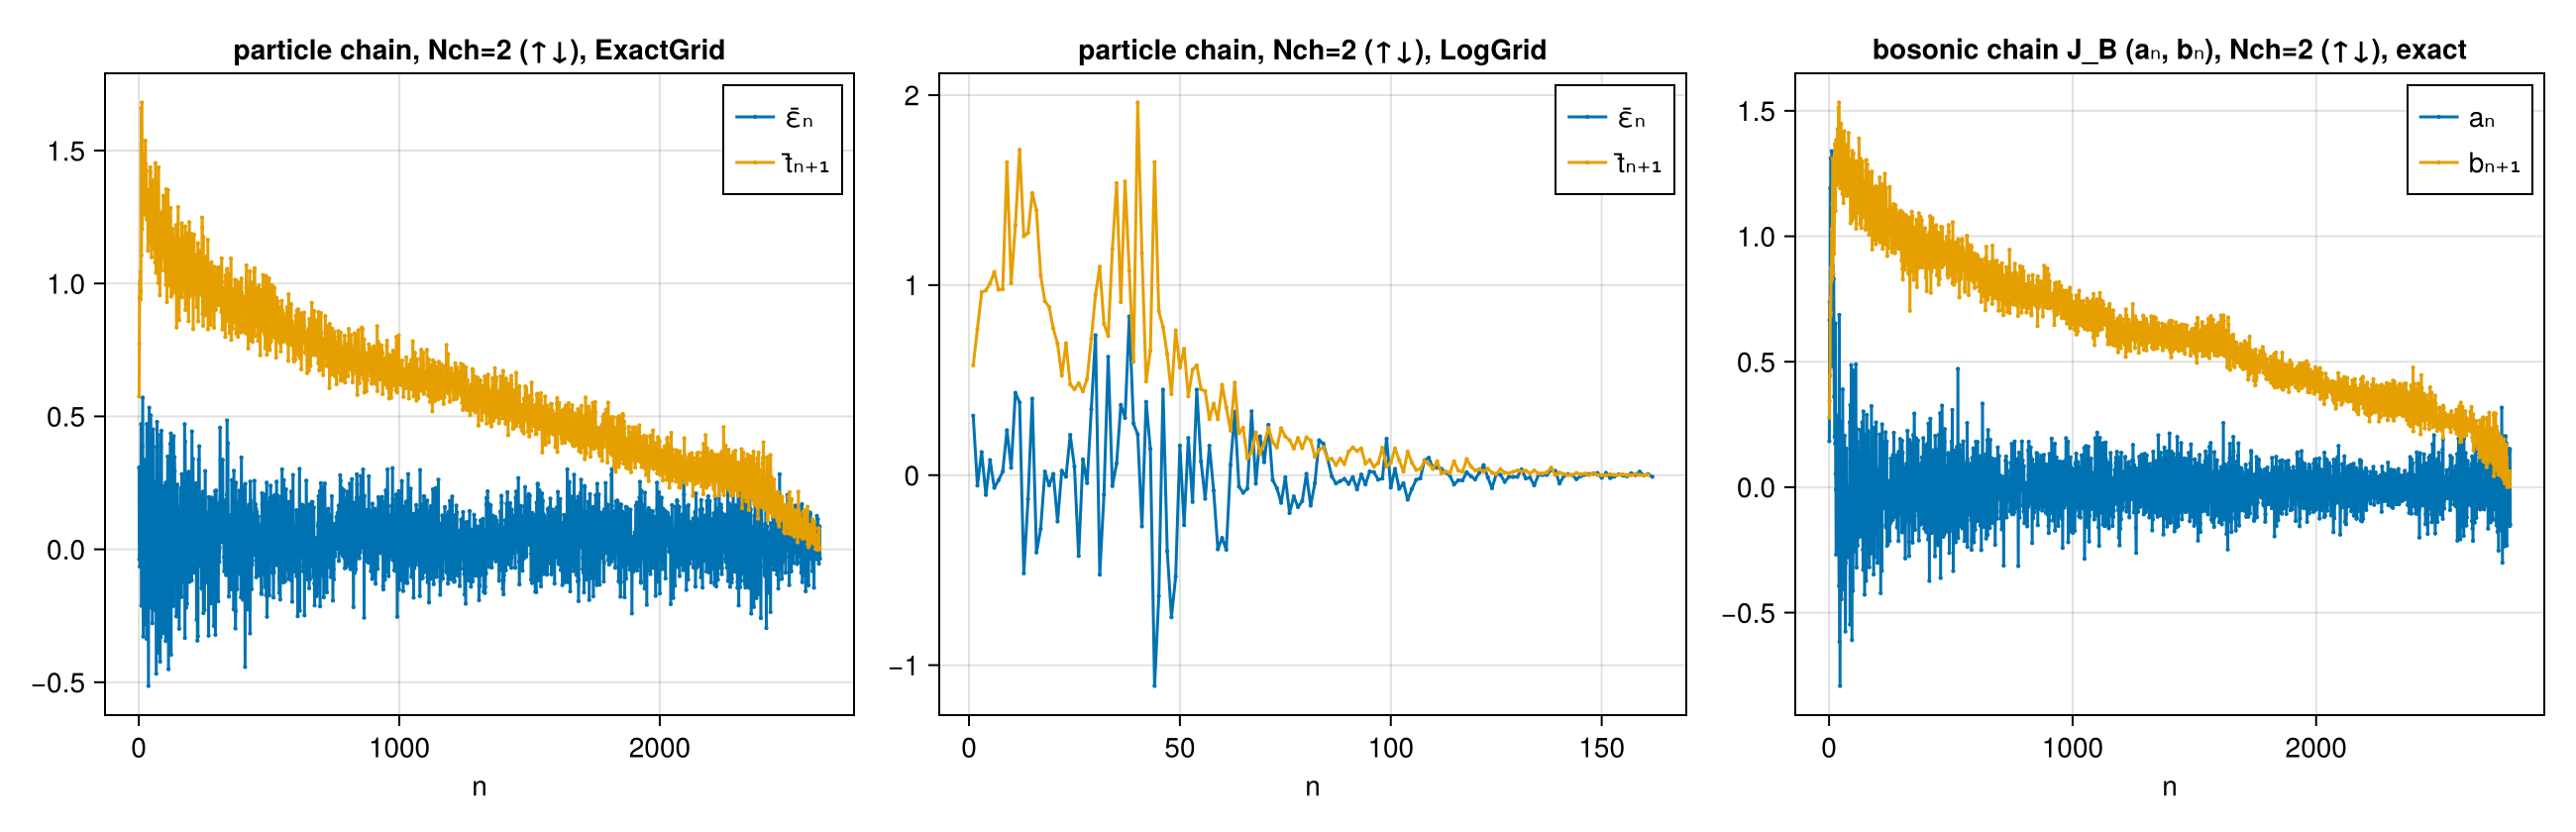

In [14]:
# chain coefficients
fig = Figure(size = (1300, 420))
for (j, gk) in enumerate((:exact, :log))
    o = R["V2 Nch=2 B=0.0 updn $gk"]; ch = o[:res].ch
    ax = Axis(fig[1, j]; xlabel = "n", title = "particle chain, Nch=2 (↑↓), $(gk === :exact ? "ExactGrid" : "LogGrid")")
    scatterlines!(ax, 1:HA.nblocks(ch.Jbar), [real(e[1]) for e in ch.Jbar.eps]; markersize = 3, label = "ε̄ₙ")
    scatterlines!(ax, 1:(HA.nblocks(ch.Jbar) - 1), [real(t[1]) for t in ch.Jbar.lower]; markersize = 3, label = "t̄ₙ₊₁")
    axislegend(ax; position = :rt)
end
o = R["V2 Nch=2 B=0.0 updn exact"]; ch = o[:res].ch
ax = Axis(fig[1, 3]; xlabel = "n", title = "bosonic chain J_B (aₙ, bₙ), Nch=2 (↑↓), exact")
scatterlines!(ax, 1:HA.nblocks(ch.JB), [e[1] for e in ch.JB.eps]; markersize = 3, label = "aₙ")
scatterlines!(ax, 1:(HA.nblocks(ch.JB) - 1), [t[1] for t in ch.JB.lower]; markersize = 3, label = "bₙ₊₁")
axislegend(ax; position = :rt)
savefig("chain_coefficients", fig)

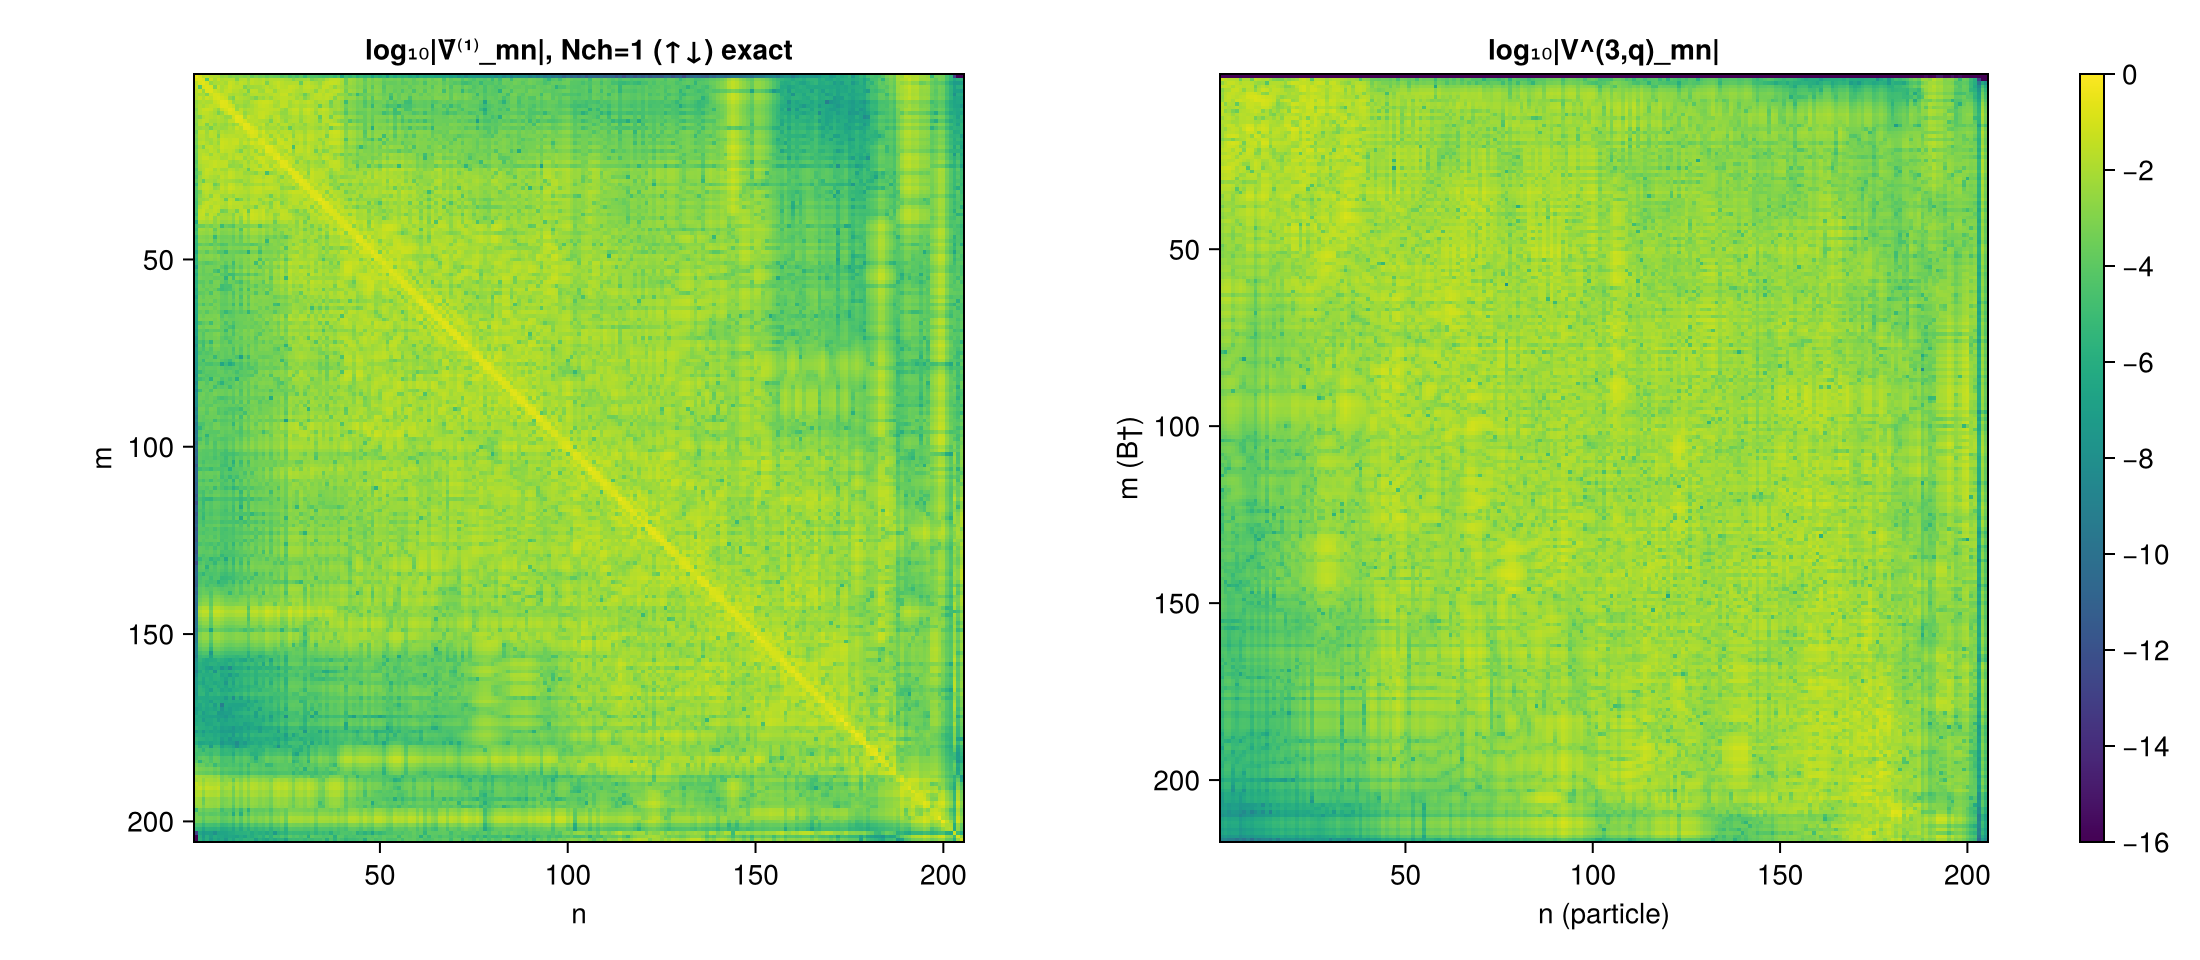

In [15]:
# couplings |V̄⁽¹⁾_mn| and |V^(3,q)_mn|
fig = Figure(size = (1100, 480))
o = R["V2 Nch=1 B=0.0 updn exact"]; cp = o[:res].cp
ax = Axis(fig[1, 1]; xlabel = "n", ylabel = "m", title = "log₁₀|V̄⁽¹⁾_mn|, Nch=1 (↑↓) exact", aspect = 1, yreversed = true)
hm = heatmap!(ax, permutedims(log10.(fl.(abs.(cp.V1)))); colormap = :viridis, colorrange = (-16, 0))
ax = Axis(fig[1, 2]; xlabel = "n (particle)", ylabel = "m (B†)", title = "log₁₀|V^(3,q)_mn|", aspect = 1, yreversed = true)
heatmap!(ax, permutedims(log10.(fl.(abs.(cp.V3[:q][1])))); colormap = :viridis, colorrange = (-16, 0))
Colorbar(fig[1, 3], hm)
savefig("couplings", fig)

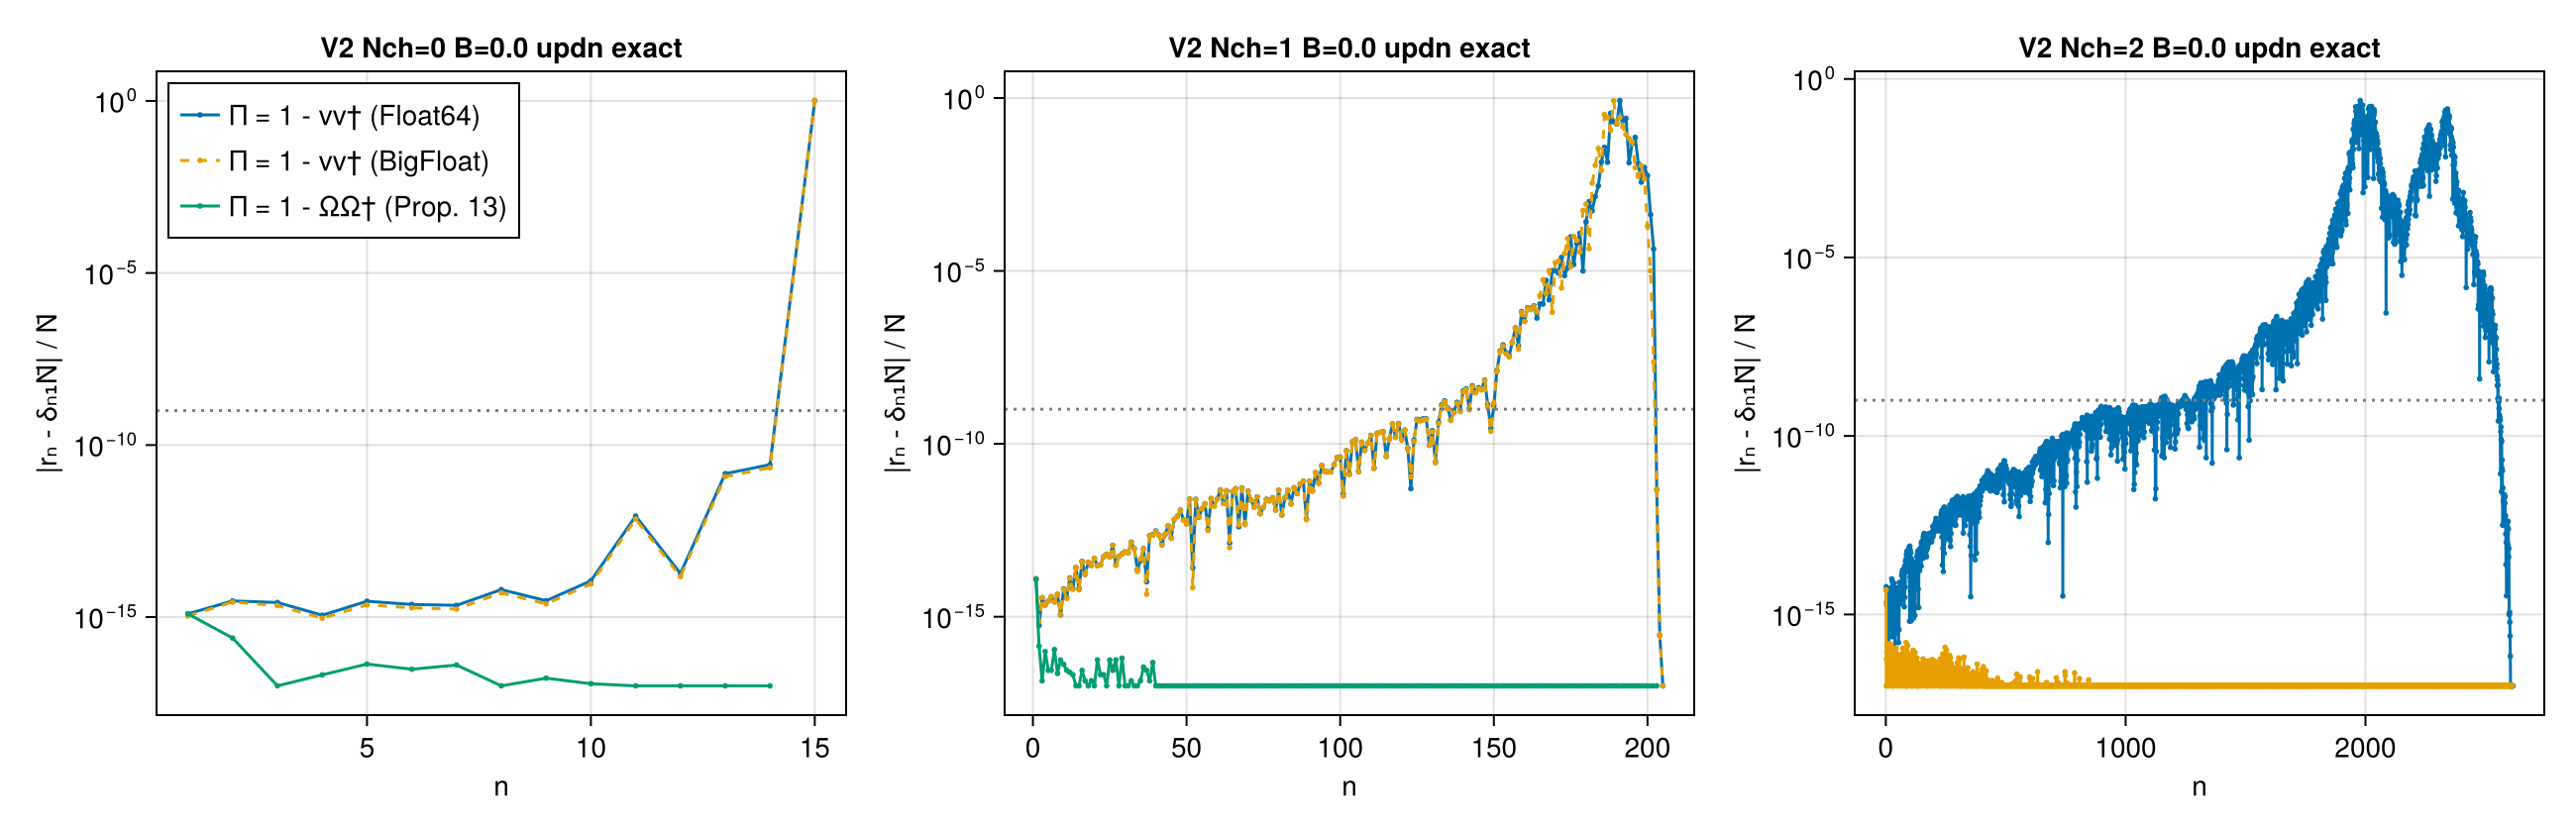

In [16]:
# bath leakage |r_n - δ_n1 N̄| / N̄: Algorithm 2 (Float64, BigFloat) and the stabilized chain
fig = Figure(size = (1300, 420))
for (j, k) in enumerate(("V2 Nch=0 B=0.0 updn exact", "V2 Nch=1 B=0.0 updn exact", "V2 Nch=2 B=0.0 updn exact"))
    o = R[k]
    ax = Axis(fig[1, j]; yscale = log10, xlabel = "n", ylabel = "|rₙ - δₙ₁N̄| / N̄", title = k)
    p = HA.leakage_profile(o[:res].ch)
    scatterlines!(ax, eachindex(p), fl.(p); markersize = 4, label = "Π = 1 - vv† (Float64)")
    haskey(o, :big) && scatterlines!(ax, eachindex(o[:big].profile), fl.(o[:big].profile); markersize = 4, linestyle = :dash, label = "Π = 1 - vv† (BigFloat)")
    scatterlines!(ax, eachindex(o[:stab].profile), fl.(o[:stab].profile); markersize = 4, label = "Π = 1 - ΩΩ† (Prop. 13)")
    hlines!(ax, [1e-9]; color = :gray, linestyle = :dot)
    j == 1 && axislegend(ax; position = :lt)
end
savefig("bath_leakage", fig)

In [17]:
for k in ("V2 Nch=0 B=0.0 updn exact", "V2 Nch=1 B=0.0 updn exact", "V2 Nch=1 B=0.0 upup exact", "V2 Nch=2 B=0.0 updn exact", "V2 Nch=2 B=0.05 upup exact")
    o = R[k]; s = o[:stab]
    @printf("%-28s R=%5d  L=%4d (stab %4d, BigFloat %s)  C4 = %.2e (BigFloat %s, stab %.1e)  dim Ω = %d  ‖Ω†Ū‖ = %.1e  ΔΣ^S = %.1e  ΔK̃ = %.1e\n",
            k, o[:checks][:R], o[:checks][:L], s.L, haskey(o, :big) ? string(o[:big].L) : "—", o[:checks][:C4],
            haskey(o, :big) ? @sprintf("%.2e", o[:big].C4) : "—", s.C4, s.Omega_dim, s.Omega_overlap, s.dSigma, s.dK)
end

V2 Nch=0 B=0.0 updn exact    R=   16  L=  15 (stab   14, BigFloat 15)  C4 = 1.03e+00 (BigFloat 1.03e+00, stab 1.2e-15)  dim Ω = 2  ‖Ω†Ū‖ = 1.3e-15  ΔΣ^S = 3.1e-16  ΔK̃ = 1.0e-15
V2 Nch=1 B=0.0 updn exact    R=  207  L= 205 (stab  203, BigFloat 205)  C4 = 8.45e-01 (BigFloat 8.35e-01, stab 1.2e-14)  dim Ω = 3  ‖Ω†Ū‖ = 1.3e-14  ΔΣ^S = 2.8e-16  ΔK̃ = 1.3e-15


V2 Nch=1 B=0.0 upup exact    R=  207  L= 205 (stab  203, BigFloat 205)  C4 = 8.30e-01 (BigFloat 8.14e-01, stab 1.2e-14)  dim Ω = 3  ‖Ω†Ū‖ = 1.3e-14  ΔΣ^S = 1.2e-16  ΔK̃ = 1.2e-14
V2 Nch=2 B=0.0 updn exact    R= 2616  L=2615 (stab 2612, BigFloat —)  C4 = 2.48e-01 (BigFloat —, stab 4.9e-15)  dim Ω = 4  ‖Ω†Ū‖ = 1.0e-14  ΔΣ^S = 2.6e-16  ΔK̃ = 2.3e-15
V2 Nch=2 B=0.05 upup exact   R= 3840  L=3839 (stab 3836, BigFloat —)  C4 = 2.01e-01 (BigFloat —, stab 5.6e-15)  dim Ω = 4  ‖Ω†Ū‖ = 1.3e-14  ΔΣ^S = 1.9e-16  ΔK̃ = 5.8e-15


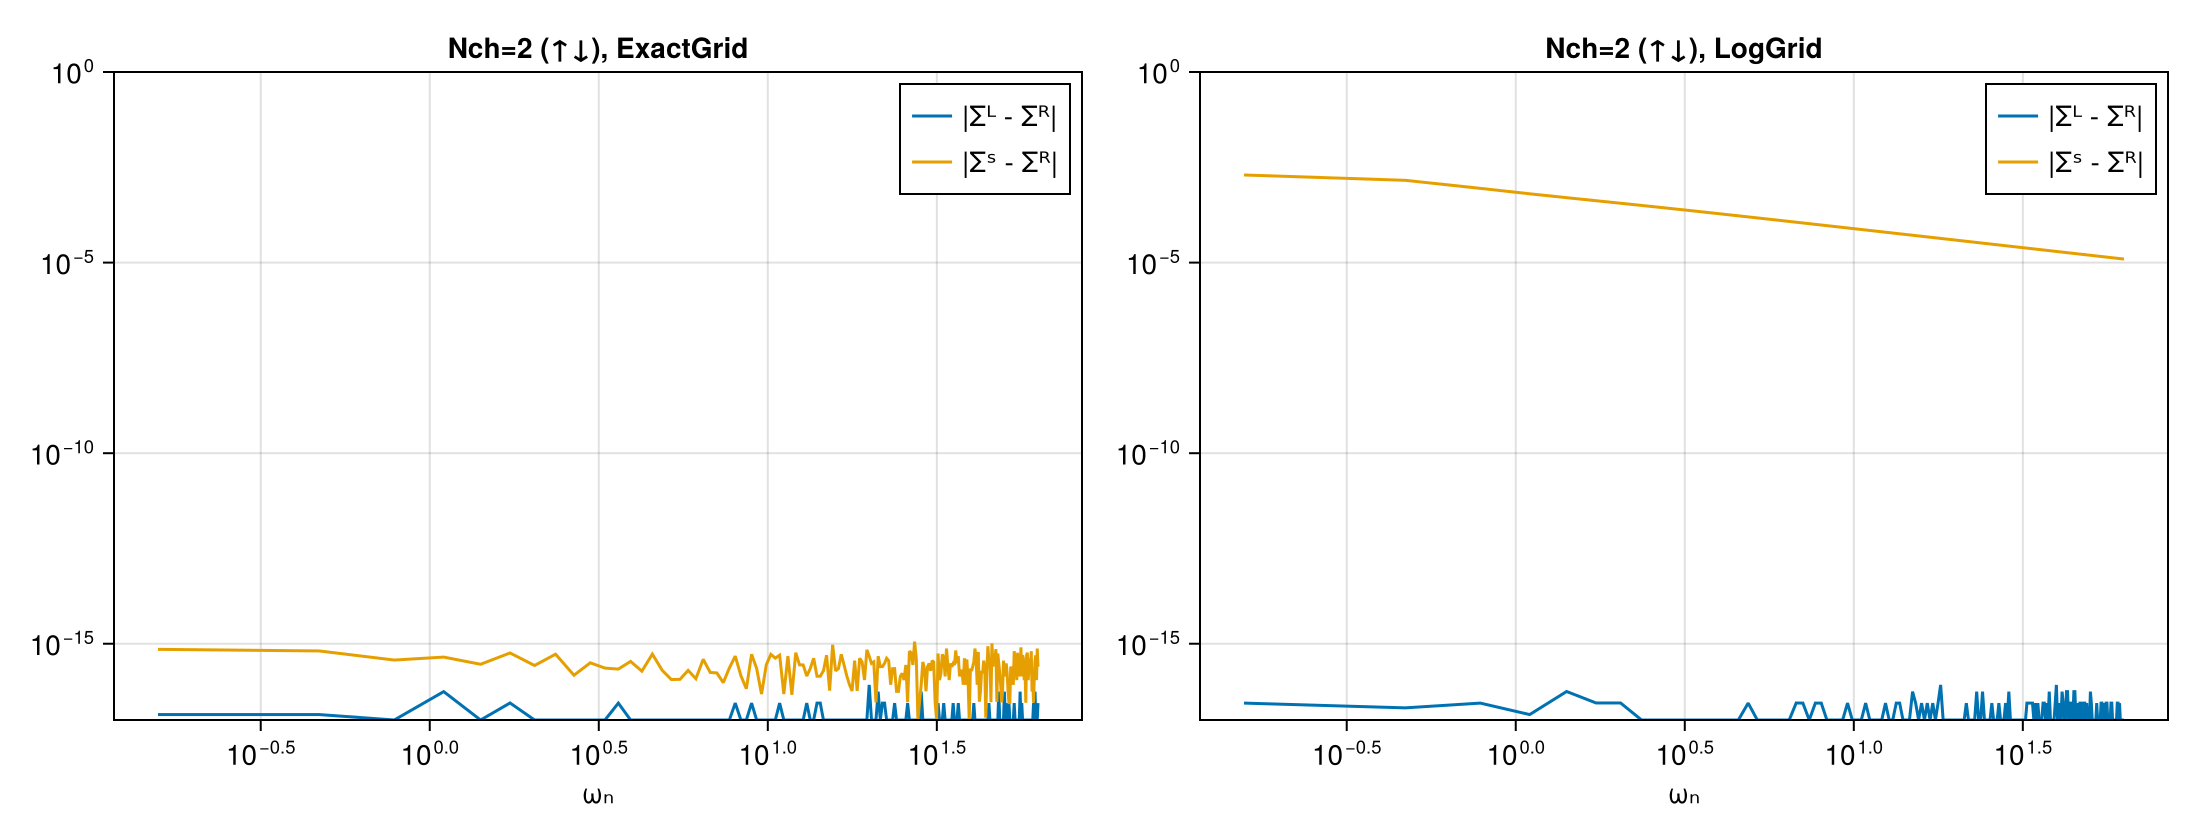

In [18]:
# |Σ^L - Σ^R| and |Σ^S - Σ^R| on the Matsubara axis, exact vs binned (why Lemma 9 is needed)
fig = Figure(size = (1100, 420))
for (j, gk) in enumerate((:exact, :log))
    o = R["V2 Nch=2 B=0.0 updn $gk"]; d = o[:data]; ch = o[:res].ch
    ns = 0:200
    LR = Float64[]; SR = Float64[]
    for n in ns
        ΣR, ΣL, ΣS = HA.sigmas(d, ch, im * HA.vk_fermionic(n, d.T))
        push!(LR, abs(ΣL[1] - ΣR[1])); push!(SR, abs(ΣS[1] - ΣR[1]))
    end
    ax = Axis(fig[1, j]; yscale = log10, xscale = log10, xlabel = "ωₙ", title = "Nch=2 (↑↓), $(gk === :exact ? "ExactGrid" : "LogGrid")")
    ωs = [HA.vk_fermionic(n, d.T) for n in ns]
    lines!(ax, ωs, fl.(LR); label = "|Σᴸ - Σᴿ|")
    lines!(ax, ωs, fl.(SR); label = "|Σˢ - Σᴿ|")
    ylims!(ax, 1e-17, 1)
    axislegend(ax; position = :rt)
end
savefig("sigma_estimators", fig)

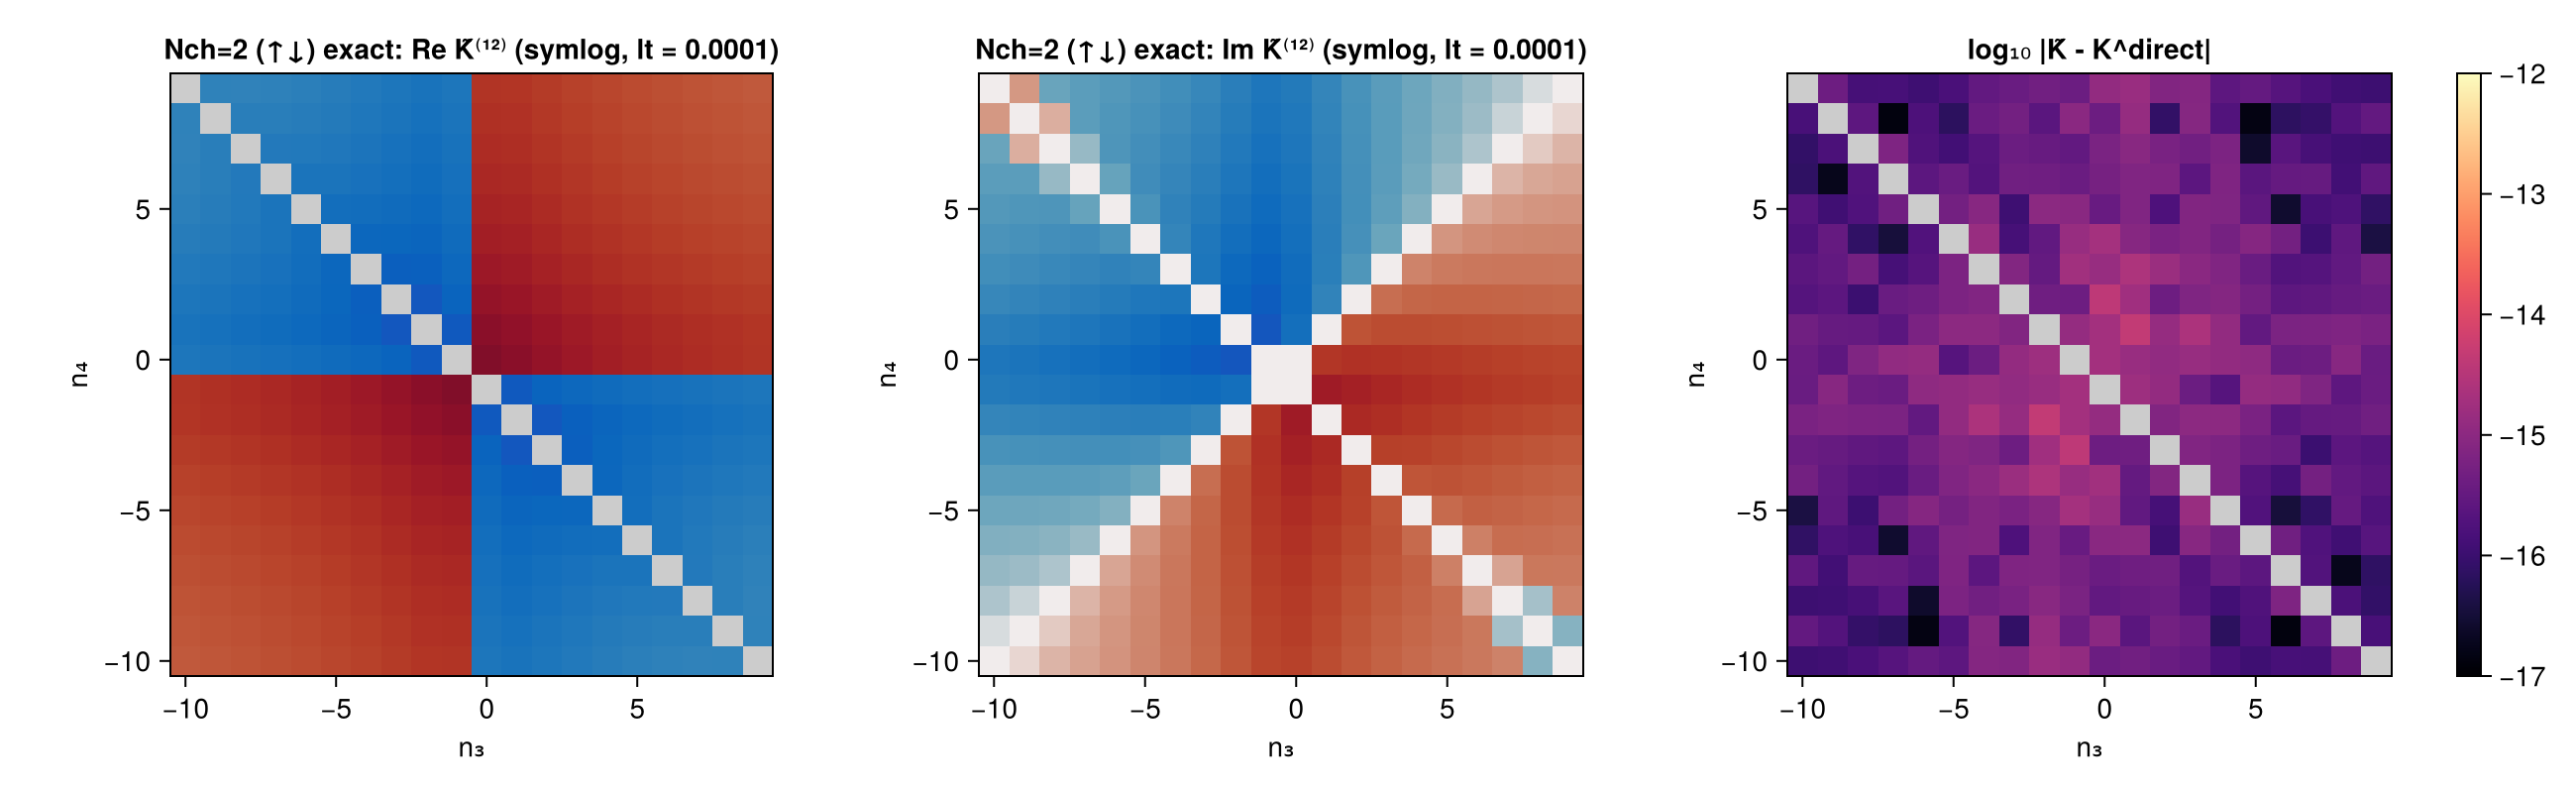

In [19]:
savefig("chain_K_exact", K_heatmaps(R["V2 Nch=2 B=0.0 updn exact"][:checks][:box]; title = "Nch=2 (↑↓) exact"))

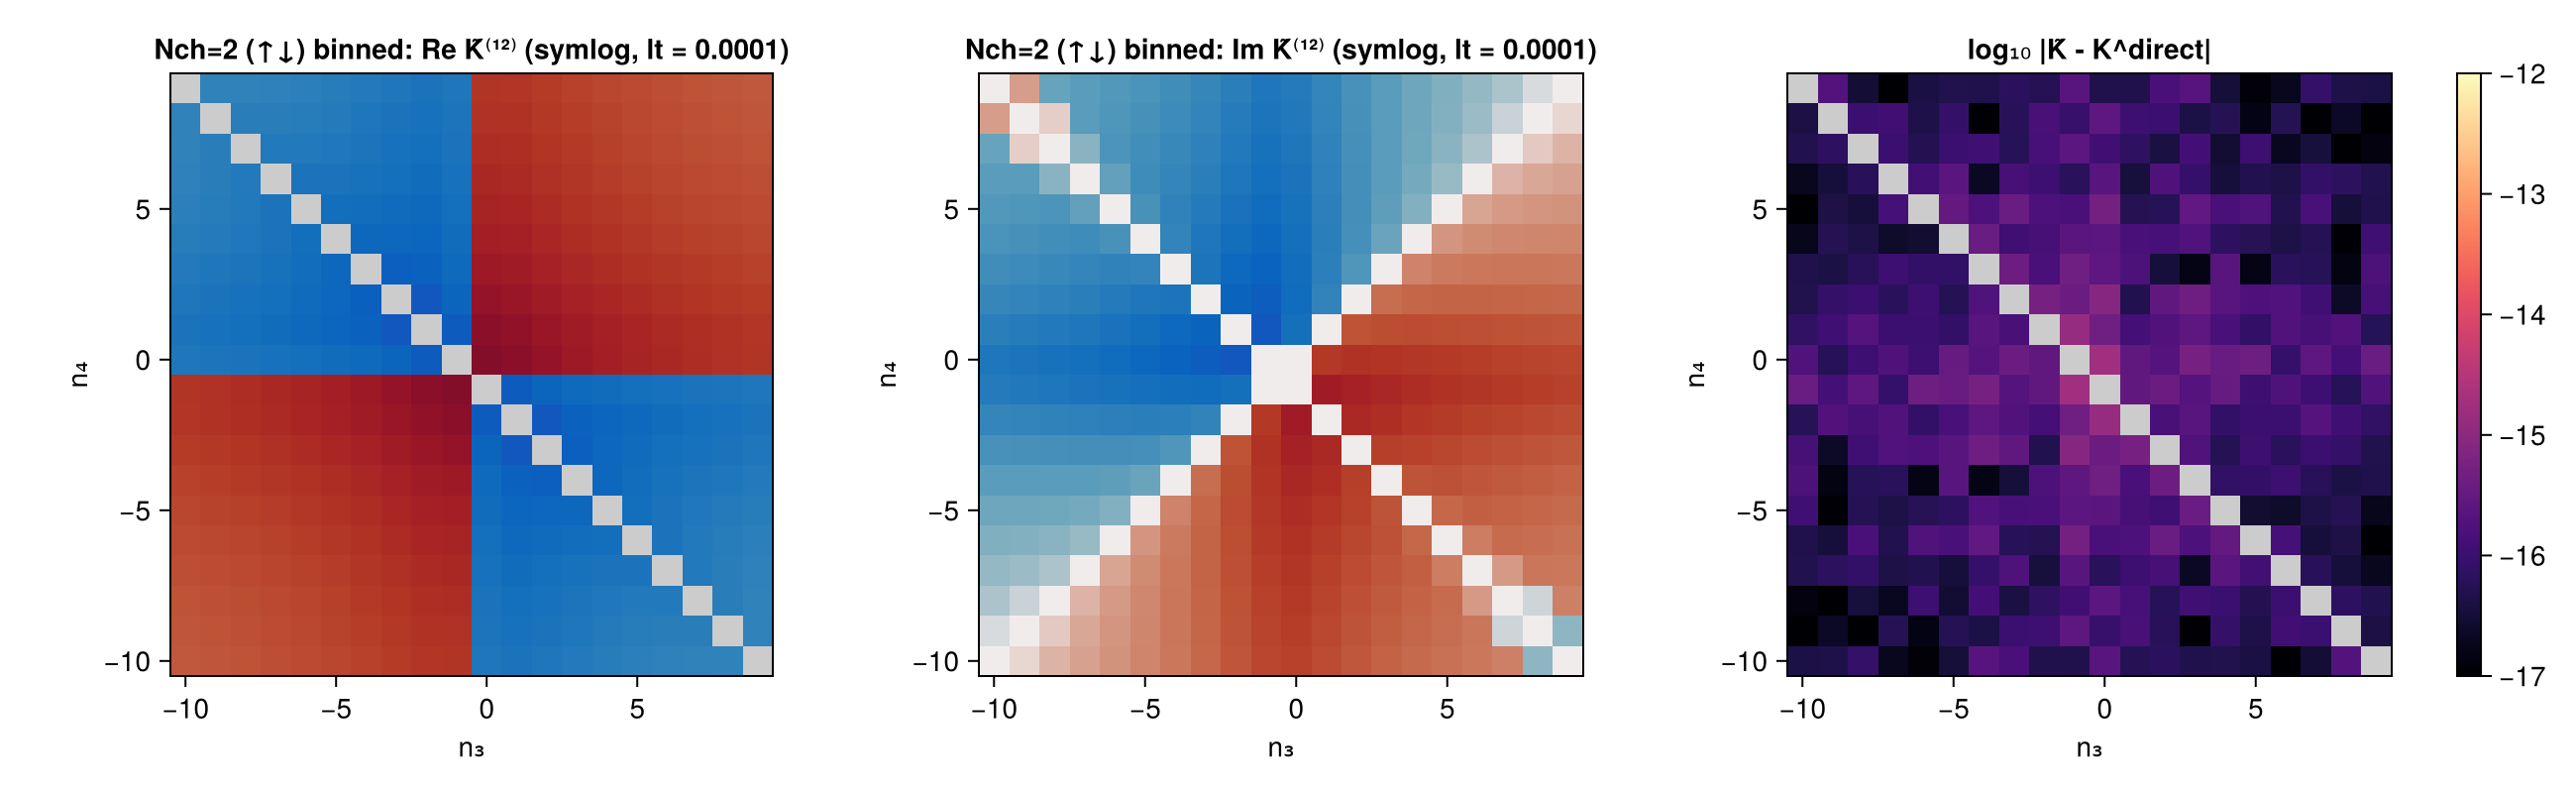

In [20]:
savefig("chain_K_binned", K_heatmaps(R["V2 Nch=2 B=0.0 updn log"][:checks][:box]; title = "Nch=2 (↑↓) binned"))

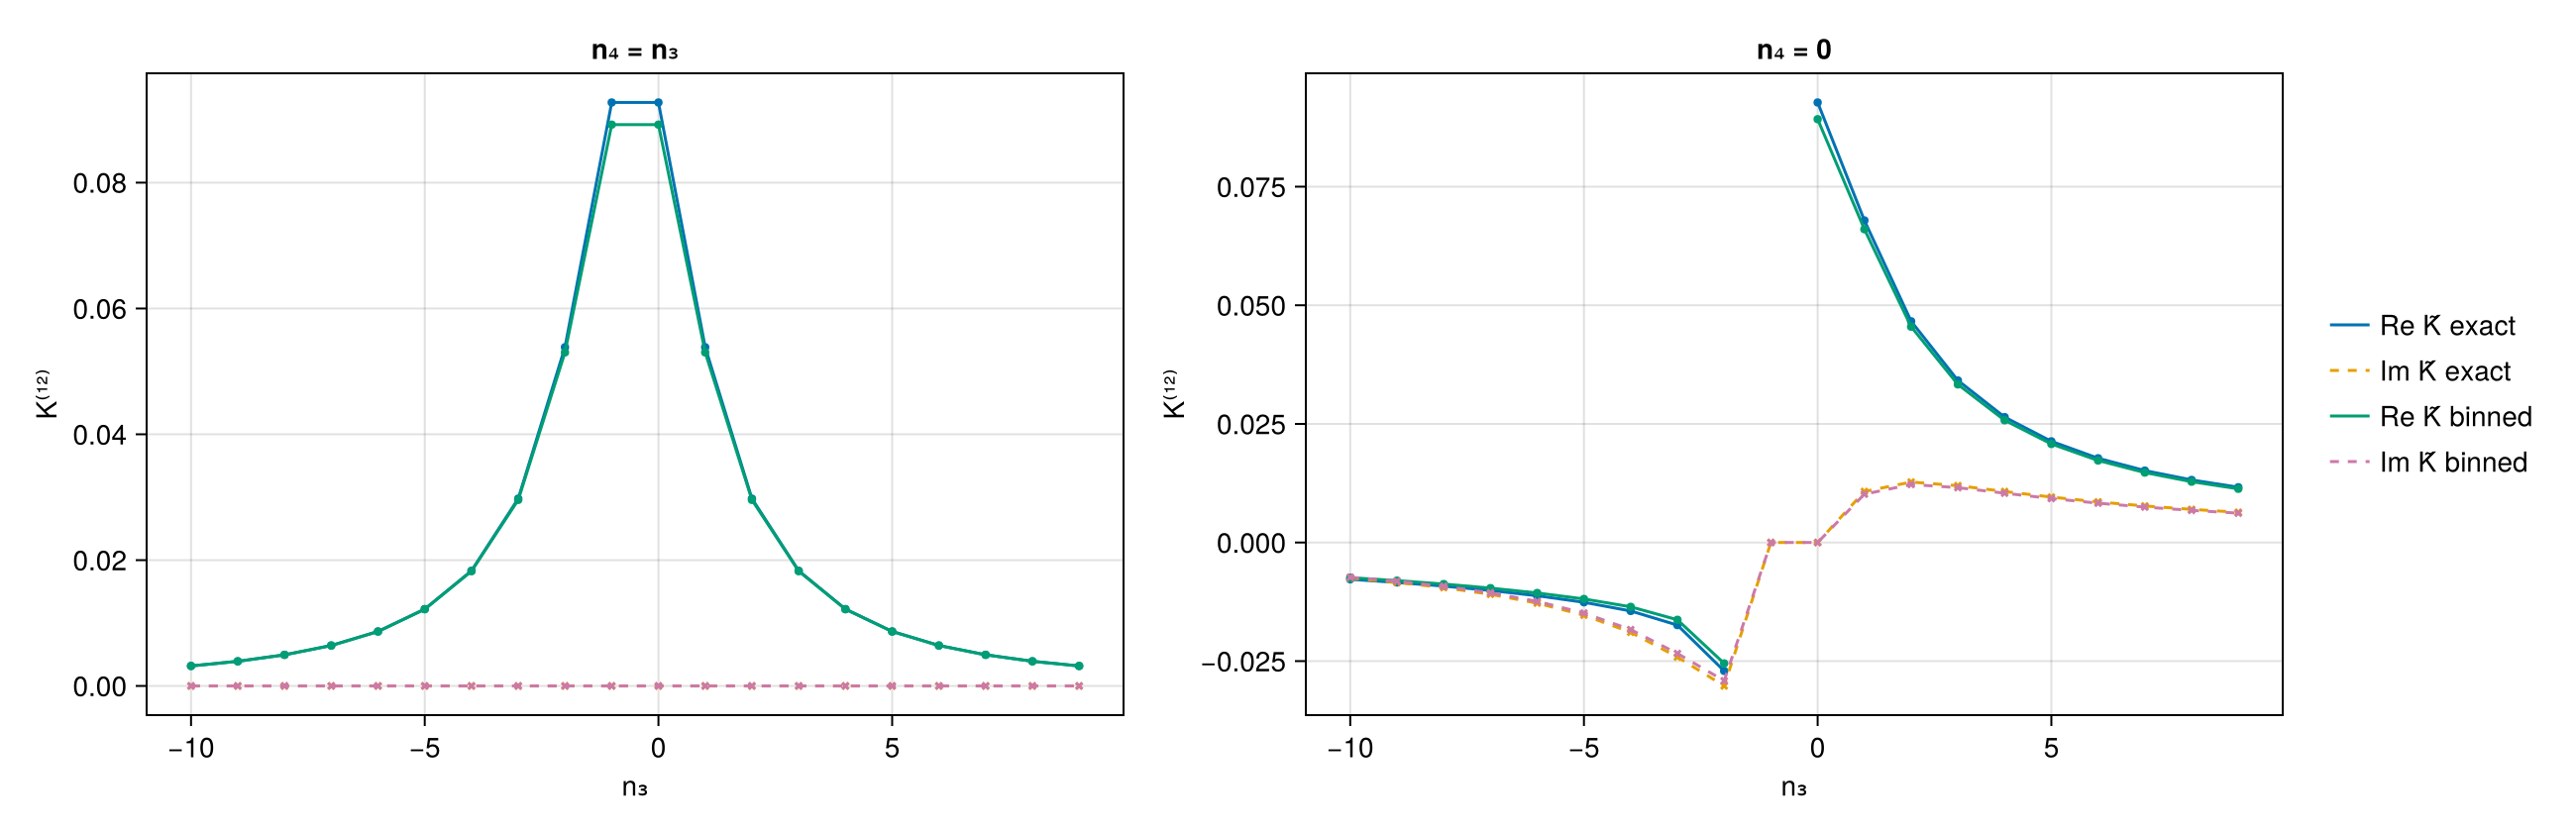

In [21]:
# two frequency slices of K̃ vs K^direct
function K_slices(keys; labels = keys)
    fig = Figure(size = (1300, 420))
    for (j, (sl, ttl)) in enumerate(((:diag, "n₄ = n₃"), (:fix, "n₄ = 0")))
        ax = Axis(fig[1, j]; xlabel = "n₃", ylabel = "K⁽¹²⁾", title = ttl)
        for (k, lb) in zip(keys, labels)
            bx = R[k][:checks][:box]
            idx = sl === :diag ? [(i, i) for i in eachindex(bx.n3s)] : [(i, findfirst(==(0), bx.n4s)) for i in eachindex(bx.n3s)]
            lines!(ax, bx.n3s, [real(bx.Kt[i...]) for i in idx]; label = "Re K̃ $lb")
            scatter!(ax, bx.n3s, [real(bx.Kd[i...]) for i in idx]; markersize = 6, marker = :circle)
            lines!(ax, bx.n3s, [imag(bx.Kt[i...]) for i in idx]; linestyle = :dash, label = "Im K̃ $lb")
            scatter!(ax, bx.n3s, [imag(bx.Kd[i...]) for i in idx]; markersize = 6, marker = :xcross)
        end
        j == 2 && Legend(fig[1, 3], ax; framevisible = false)
    end
    fig
end
savefig("chain_K_slices", K_slices(["V2 Nch=2 B=0.0 updn exact", "V2 Nch=2 B=0.0 updn log"]; labels = ["exact", "binned"]))

case                                S-N̄²        Ū₁   spectra   weights       Σ^S   L_zac       L n_agree
V2 Nch=1 B=0.0 updn exact        8.0e-16   8.3e-16   3.2e-15   1.2e-13   3.4e-14     199     205      91


V2 Nch=1 B=0.0 updn log          1.1e-16   2.8e-16   4.5e-15   5.7e-14   2.2e-14      84      86      28
V2 Nch=1 B=0.0 upup exact        8.0e-16   8.3e-16   2.9e-15   1.1e-13   3.5e-14     201     205      91
V2 Nch=1 B=0.0 upup log          1.1e-16   2.8e-16   4.5e-15   5.7e-14   2.2e-14      84      86      28
V2 Nch=2 B=0.0 updn exact        3.5e-16   1.4e-16   5.6e-15   1.6e-13   5.8e-14    2551    2615     209
V2 Nch=2 B=0.0 updn log          1.2e-16   3.6e-16   3.6e-15   2.6e-14   9.1e-15     162     162      33
V2 Nch=2 B=0.0 upup exact        3.5e-16   1.4e-16   1.6e-14   1.2e-12   4.6e-13    2544    2615     210
V2 Nch=2 B=0.0 upup log          1.2e-16   3.6e-16   3.6e-15   2.6e-14   9.1e-15     162     162      33
V1 atom T=0.1 updn               1.1e-16   3.3e-16   4.0e-16   2.8e-14   1.2e-15       1       1       1


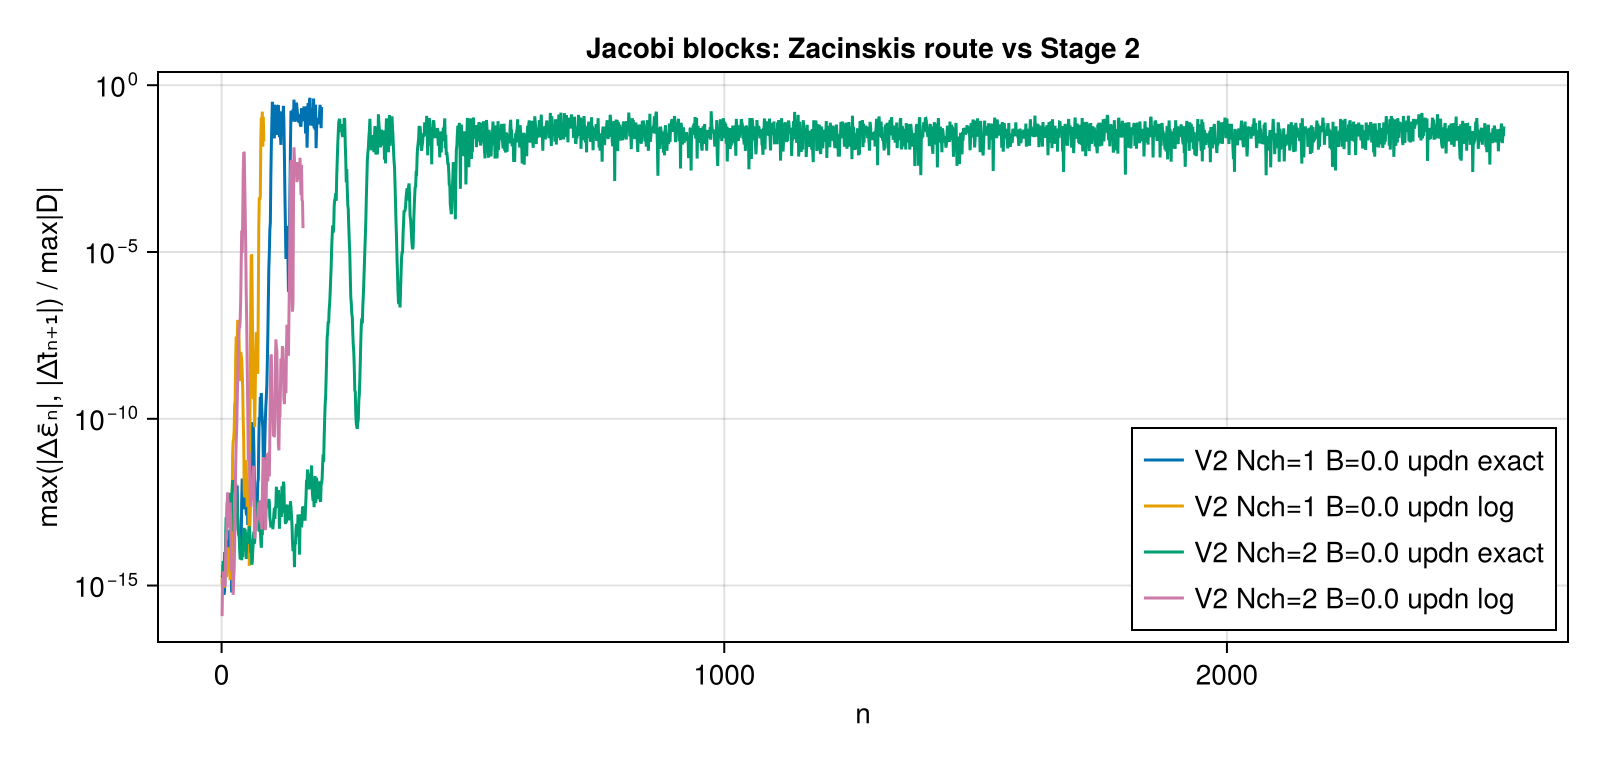

In [22]:
# Zacinskis cross-check (C2, [VD] Prop. 11)
@printf("%-30s %9s %9s %9s %9s %9s %7s %7s %7s\n", "case", "S-N̄²", "Ū₁", "spectra", "weights", "Σ^S", "L_zac", "L", "n_agree")
for k in vcat(["V2 Nch=$N B=0.0 $c $g" for N in (1, 2) for c in (:updn, :upup) for g in (:exact, :log)], ["V1 atom T=0.1 updn"])
    z = R[k][:checks][:zac]
    @printf("%-30s %9.1e %9.1e %9.1e %9.1e %9.1e %7d %7d %7d\n", k, z.S_err, z.U1_err, z.spec_err, z.weight_err, z.sigma_err, z.L_zac, z.L_chain, z.n_agree)
end
fig = Figure(size = (800, 380))
ax = Axis(fig[1, 1]; yscale = log10, xlabel = "n", ylabel = "max(|Δε̄ₙ|, |Δt̄ₙ₊₁|) / max|D|", title = "Jacobi blocks: Zacinskis route vs Stage 2")
for k in ("V2 Nch=1 B=0.0 updn exact", "V2 Nch=1 B=0.0 updn log", "V2 Nch=2 B=0.0 updn exact", "V2 Nch=2 B=0.0 updn log")
    z = R[k][:checks][:zac]
    lines!(ax, eachindex(z.block_dev), fl.(z.block_dev); label = k)
end
axislegend(ax; position = :rb)
savefig("zacinskis_blocks", fig)

## 4. Untruncated NRG (V3a)

The same chains with `NRGParams(N = Nch, Nkeep = typemax(Int))`: without truncation the Anders–Schiller basis is the
exact eigenbasis, so NRG data must equal the binned ED data of V2b (mpNRG V3c accuracy, about $10^{-14}$), and all
guaranteed checks must hold. `DiscreteData` from NRG and from ED are compared directly.

In [23]:
@printf("%-30s %9s %9s %9s\n", "case", "max|ΔW̃|", "max|Δw^B|", "max|Δs|")
for N in (1, 2), f in (0.0, 0.05), c in (:updn, :upup)
    k = "V3a Nch=$N B=$f $c"; df = R[k][:diff]
    @printf("%-30s %9.1e %9.1e %9.1e\n", k, df.W, df.wB, df.s)
end
println()
chain_table(["V3a Nch=$N B=$f $c" for N in (1, 2) for f in (0.0, 0.05) for c in (:updn, :upup)])

case                             max|ΔW̃| max|Δw^B|   max|Δs|
V3a Nch=1 B=0.0 updn             4.4e-15   3.6e-16   2.8e-15


V3a Nch=1 B=0.0 upup             4.4e-15   5.8e-16   5.2e-16
V3a Nch=1 B=0.05 updn            1.7e-15   5.8e-16   8.6e-16
V3a Nch=1 B=0.05 upup            1.7e-15   3.6e-16   3.5e-16
V3a Nch=2 B=0.0 updn             9.2e-15   9.4e-16   4.7e-15
V3a Nch=2 B=0.0 upup             9.2e-15   7.9e-16   1.4e-15
V3a Nch=2 B=0.05 updn            5.3e-15   1.1e-15   3.2e-15
V3a Nch=2 B=0.05 upup            5.3e-15   3.4e-16   7.7e-16

case                                 bins     R    L  L_B        C1        C2        C3        C4   C4 stab        C5        C6        C7        C8     t [s]
V3a Nch=1 B=0.0 updn                  195    87   86   55   2.0e-15   7.0e-14   2.0e-01   3.7e-01         —   0.0e+00   5.2e-16   5.8e-16   3.1e-15      29.6
V3a Nch=1 B=0.0 upup                  195    87   86   55   2.0e-15   7.0e-14   2.0e-01   3.7e-01         —   0.0e+00   7.2e-16   5.0e-16   3.3e-14       1.2
V3a Nch=1 B=0.05 updn                 195   102  101   57   2.6e-15   3.6e-14   2.4e-01   5.7e-01 

max|K̃(NRG) - K̃(ED)| / max|K̃| = 2.4e-14


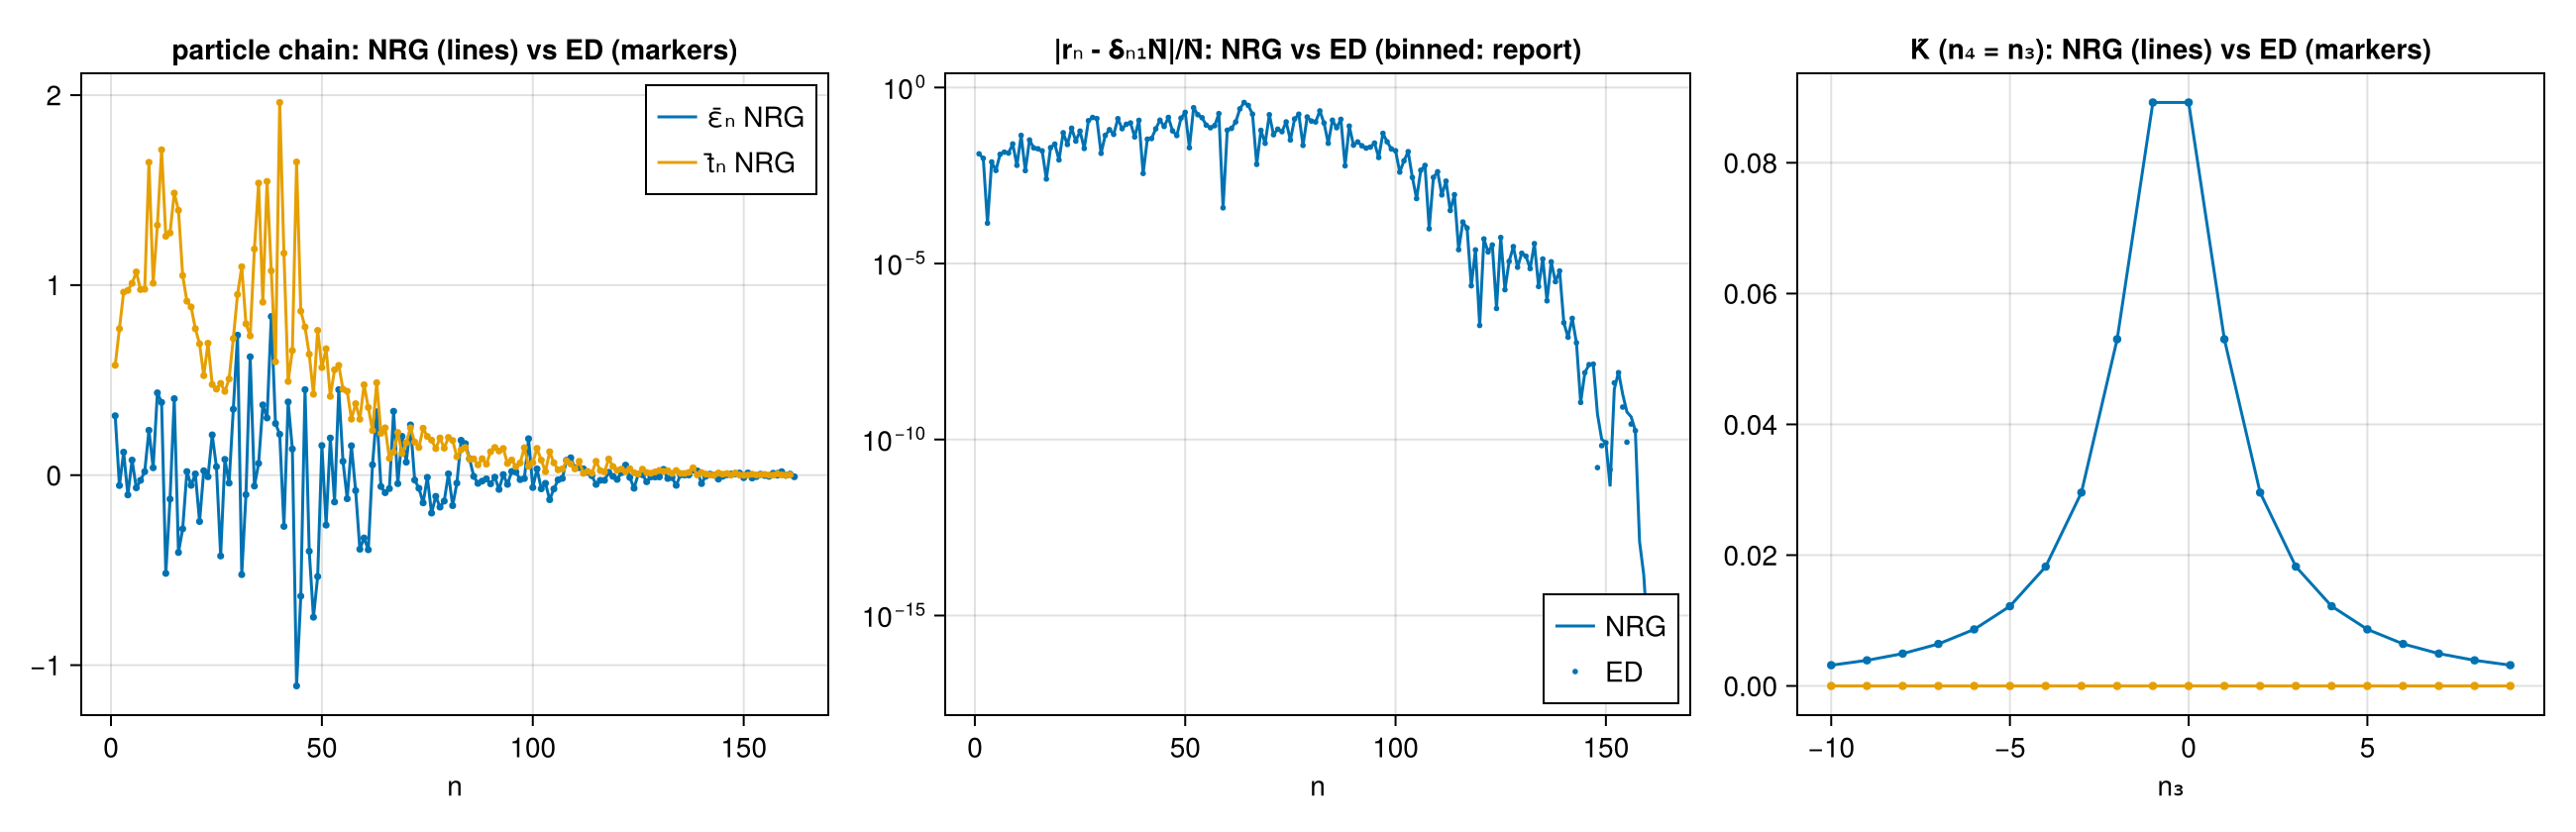

In [24]:
fig = Figure(size = (1300, 420))
o = R["V3a Nch=2 B=0.0 updn"]; e = R["V2 Nch=2 B=0.0 updn log"]
ch = o[:res].ch; che = e[:res].ch
ax = Axis(fig[1, 1]; xlabel = "n", title = "particle chain: NRG (lines) vs ED (markers)")
lines!(ax, [real(x[1]) for x in ch.Jbar.eps]; label = "ε̄ₙ NRG"); scatter!(ax, [real(x[1]) for x in che.Jbar.eps]; markersize = 5)
lines!(ax, [real(x[1]) for x in ch.Jbar.lower]; label = "t̄ₙ NRG"); scatter!(ax, [real(x[1]) for x in che.Jbar.lower]; markersize = 5)
axislegend(ax)
ax = Axis(fig[1, 2]; yscale = log10, xlabel = "n", title = "|rₙ - δₙ₁N̄|/N̄: NRG vs ED (binned: report)")
lines!(ax, fl.(HA.leakage_profile(ch)); label = "NRG"); scatter!(ax, fl.(HA.leakage_profile(che)); markersize = 4, label = "ED")
axislegend(ax; position = :rb)
bx = o[:checks][:box]; bxe = e[:checks][:box]
ax = Axis(fig[1, 3]; xlabel = "n₃", title = "K̃ (n₄ = n₃): NRG (lines) vs ED (markers)")
lines!(ax, bx.n3s, [real(bx.Kt[i, i]) for i in eachindex(bx.n3s)]); scatter!(ax, bxe.n3s, [real(bxe.Kt[i, i]) for i in eachindex(bxe.n3s)]; markersize = 6)
lines!(ax, bx.n3s, [imag(bx.Kt[i, i]) for i in eachindex(bx.n3s)]); scatter!(ax, bxe.n3s, [imag(bxe.Kt[i, i]) for i in eachindex(bxe.n3s)]; markersize = 6)
m_ = .!isnan.(real.(bx.Kt))
@printf("max|K̃(NRG) - K̃(ED)| / max|K̃| = %.1e\n", maximum(abs, bx.Kt[m_] - bxe.Kt[m_]) / maximum(abs, bxe.Kt[m_]))
savefig("v3a_overlay", fig)

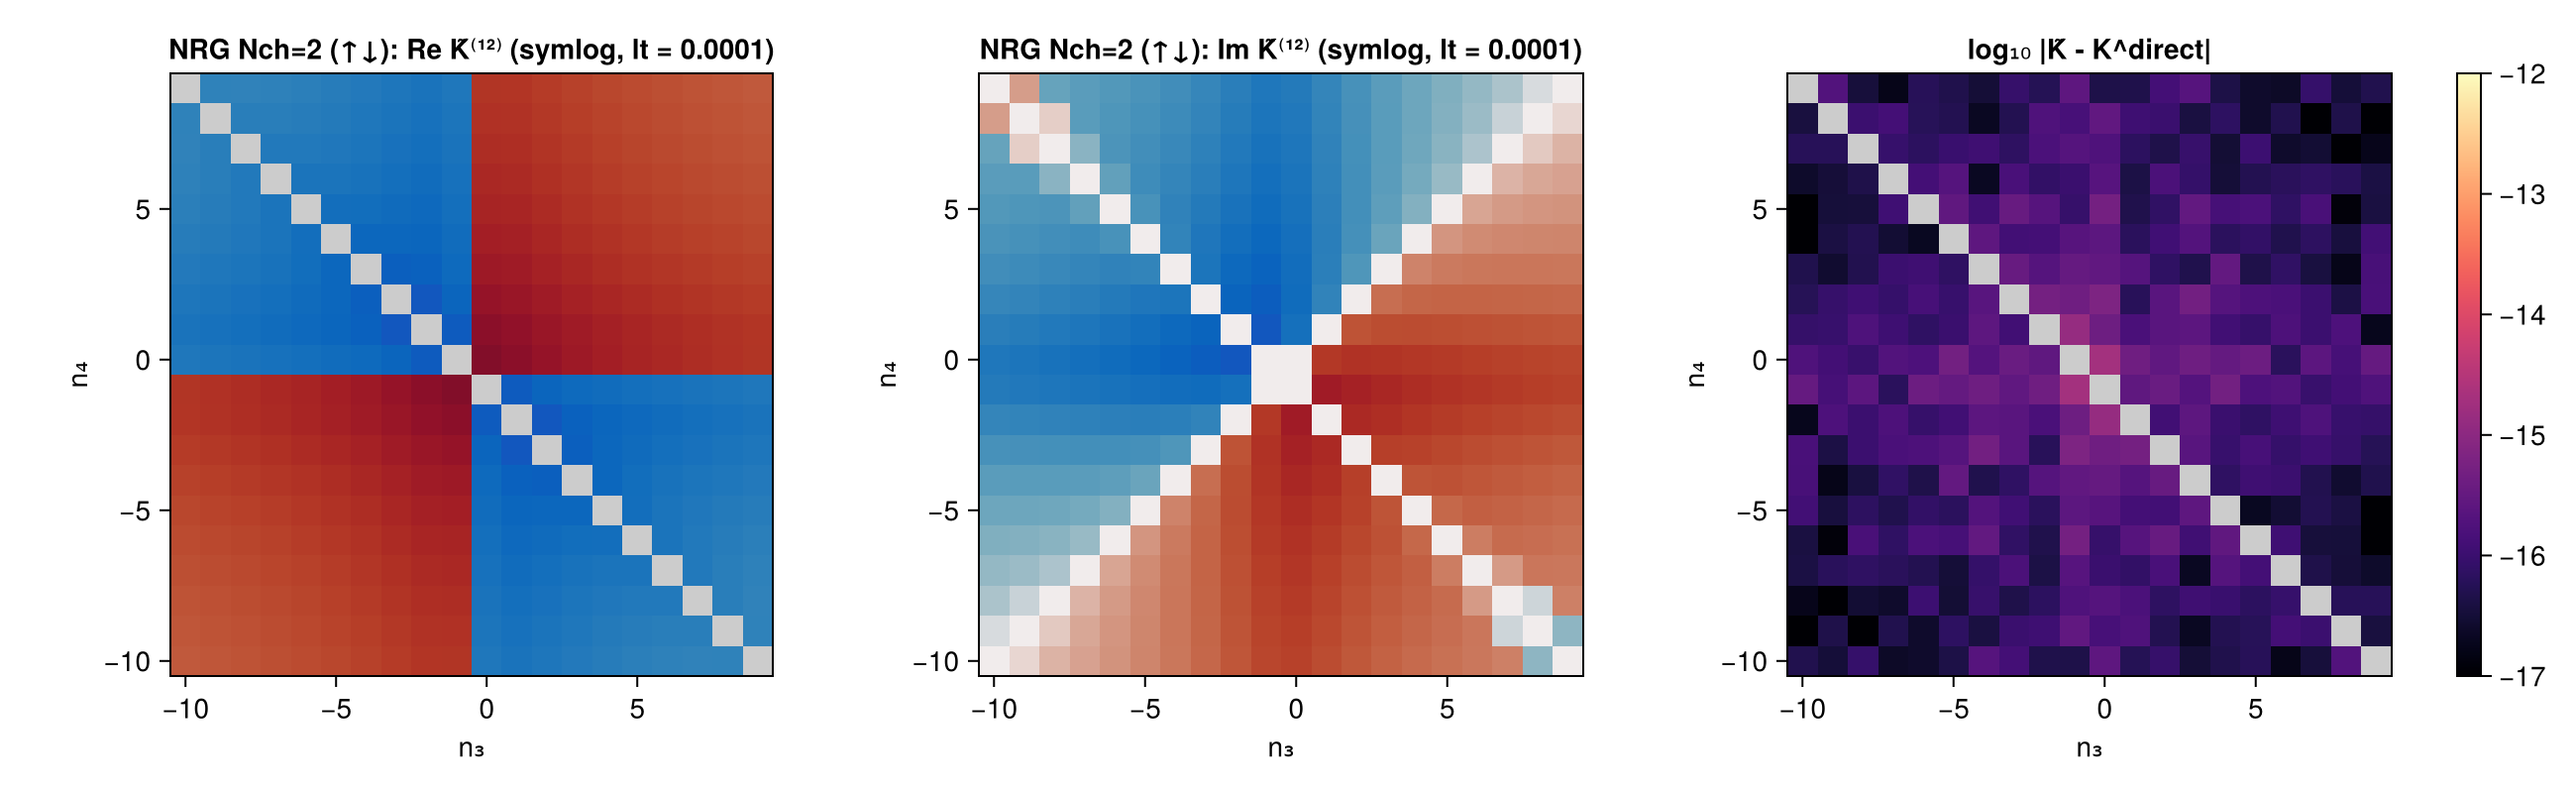

In [25]:
savefig("v3a_K", K_heatmaps(R["V3a Nch=2 B=0.0 updn"][:checks][:box]; title = "NRG Nch=2 (↑↓)"))

## 5. Decoupled tail, truncated NRG (V3b)

As mpNRG V4d: chain of length 3 with $t_n=\varepsilon_n=0$ for $n>n_c=1$, `Nkeep = 40`, $T=0.05$. With the decoupled
tail the Anders–Schiller states are exact eigenstates and the NRG approximation, the shell-diagonal expansion and the
slicing are exact, so **truncated** NRG data equal ED of the same chain; this is the only regime in which truncated data
are exact. Compared with ED of the same chain on the same grid. A failure here would be a bug, not NRG physics.

In [26]:
for c in (:updn, :upup)
    o = R["V3b $c"]; tr = o[:data].meta[:truncation]; df = o[:diff]
    @printf("%s: kept per shell %s, discarded %s; data vs ED: max|ΔW̃| = %.1e, max|Δw^B| = %.1e, max|Δs| = %.1e\n",
            chs(c), tr.kept, tr.disc, df.W, df.wB, df.s)
end
println()
chain_table(["V3b updn", "V3b upup"])
println("\nED of the same chain (binned, same grid):")
for c in (:updn, :upup)
    ce = R["V3b $c"][:ed][:checks]
    @printf("  %s: C1 %.1e  C5 %.1e  C6 %.1e  C7 %.1e  C8 %.1e; K̃(NRG) vs K̃(ED): %.1e\n", chs(c), ce[:C1], ce[:C5], ce[:C6], ce[:C7], ce[:C8],
            (bx = R["V3b $c"][:checks][:box]; bxe = ce[:box]; m_ = .!isnan.(real.(bx.Kt)); maximum(abs, bx.Kt[m_] - bxe.Kt[m_]) / maximum(abs, bxe.Kt[m_])))
end

(↑↓): kept per shell [16, 42, 40, 0], discarded [0, 22, 128, 160]; data vs ED: max|ΔW̃| = 3.2e-15, max|Δw^B| = 7.2e-16, max|Δs| = 2.8e-15
(↑↑): kept per shell [16, 42, 40, 0], discarded [0, 22, 128, 160]; data vs ED: max|ΔW̃| = 3.2e-15, max|Δw^B| = 5.4e-16, max|Δs| = 4.9e-16



case                                 bins     R    L  L_B        C1        C2        C3        C4   C4 stab        C5        C6        C7        C8     t [s]
V3b updn                              195    87   86   55   1.2e-15   7.1e-14   2.0e-01   3.7e-01         —   0.0e+00   3.7e-16   4.9e-16   3.4e-15       3.1
V3b upup                              195    87   86   55   1.2e-15   7.1e-14   2.0e-01   3.7e-01         —   0.0e+00   1.1e-15   9.9e-16   3.0e-14       2.3

ED of the same chain (binned, same grid):
  (↑↓): C1 2.1e-15  C5 0.0e+00  C6 3.2e-16  C7 4.9e-16  C8 3.2e-15; K̃(NRG) vs K̃(ED): 2.9e-15
  (↑↑): C1 2.1e-15  C5 0.0e+00  C6 6.8e-16  C7 4.0e-16  C8 2.8e-14; K̃(NRG) vs K̃(ED): 2.9e-14


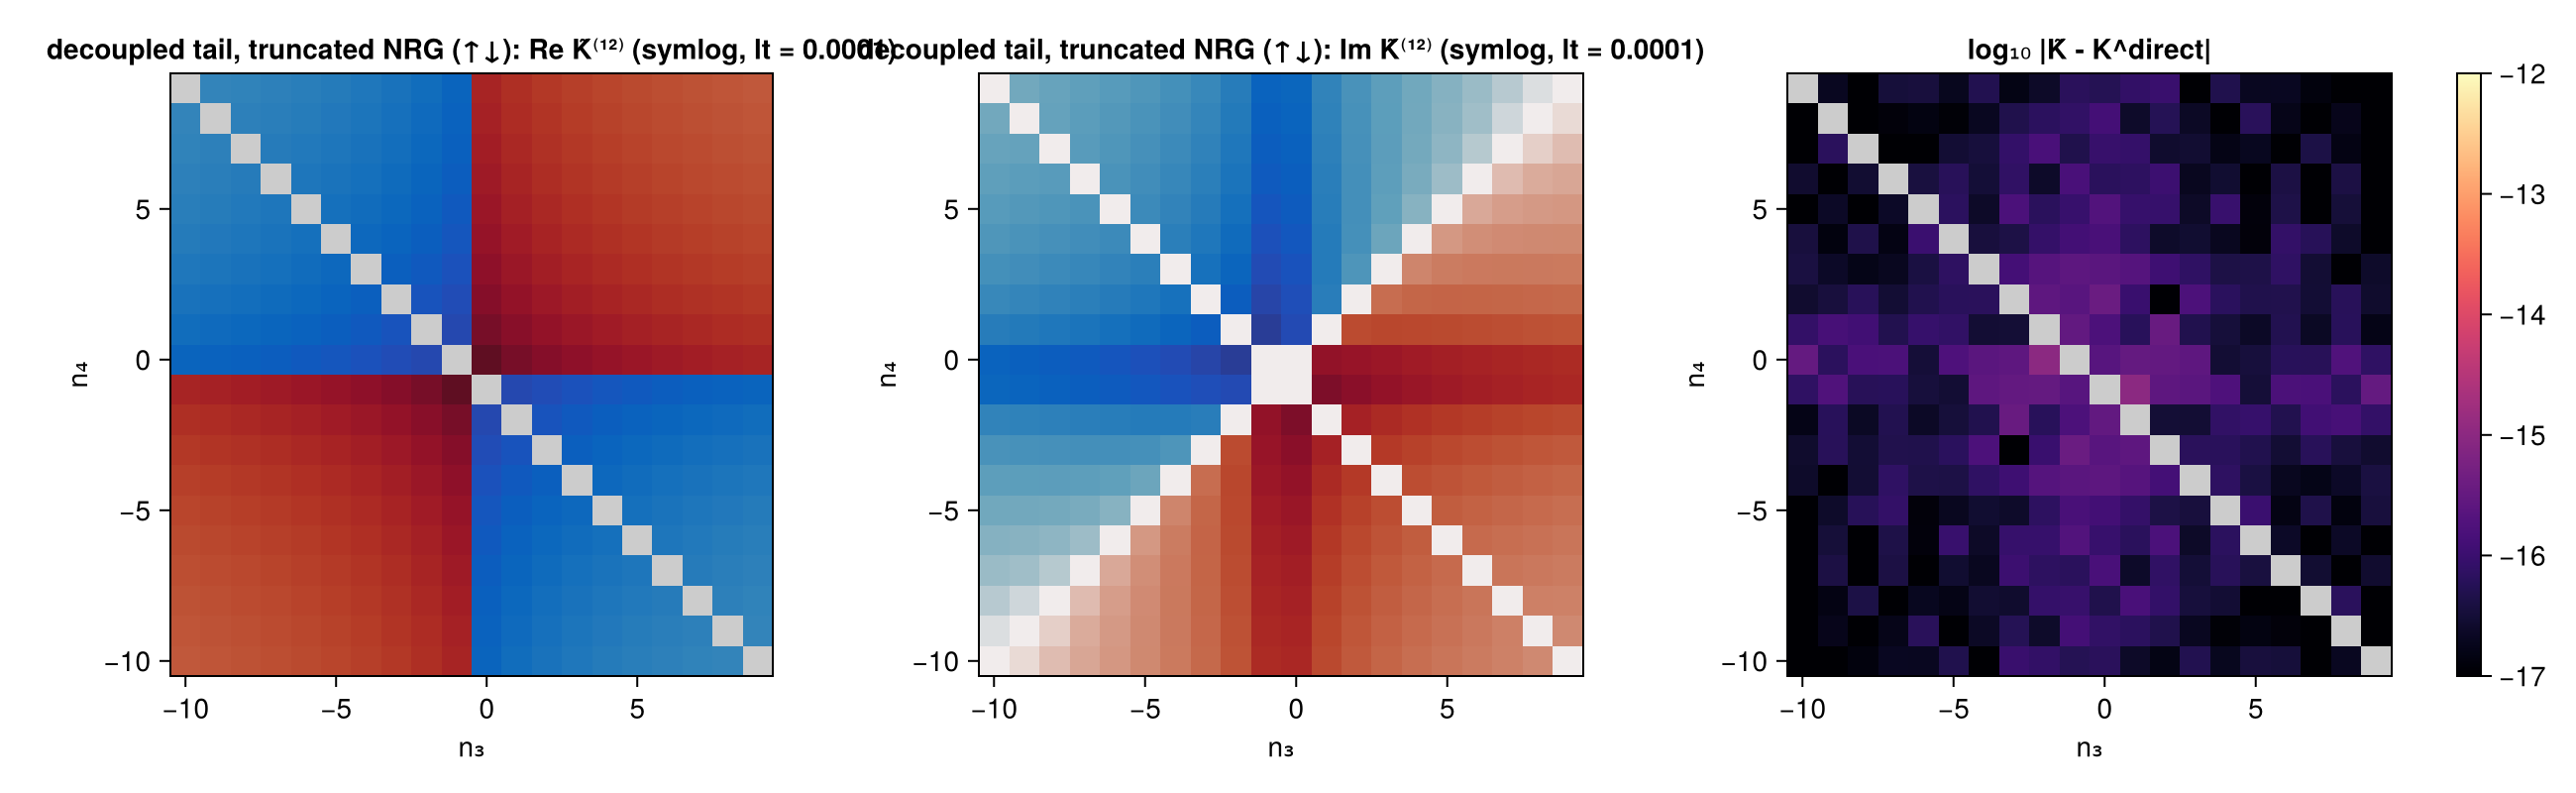

In [27]:
savefig("v3b_K", K_heatmaps(R["V3b updn"][:checks][:box]; title = "decoupled tail, truncated NRG (↑↓)"))

## 7. Findings

**F1 — C4 (bath leakage) fails for exact Wilson-chain data without the stabilization.** The particle chain of
Algorithm 2 with $\Pi=1-vv^\dagger$ keeps running after the cyclic space of $Qq^\dagger$ is exhausted and enters the
single-particle invariant subspace $\mathbb K_0\ominus d^\dagger$ ([VD] Lemma 12), where $r_n=\bar U_n^\dagger Dv$ is
$O(1)$. The guaranteed tolerance $10^{-9}$ (V2a) is violated in every V2a chain case (table above). Evidence:

* the leak $|r_n-\delta_{n1}\bar N|/\bar N$ starts at $\sim10^{-15}$ at $n=1$ and grows roughly exponentially along
  the chain (plot "bath leakage" in Sec. 3), crossing $10^{-9}$ after $\sim130$ levels for the 64-state chain and
  reaching $O(1)$ in the last levels; the unstabilized chain is longer than the stabilized one by
  $\dim\Omega-1$ = number of bath levels (16-state chain: $L=15=\dim{\rm ran}\,P$ vs 14);
* **BigFloat (128 bit) gives the same leak** (same chain length, same C4 to two digits), so the seed is not Float64
  rounding in the Lanczos recursion but the $\sim10^{-16}$ accuracy with which the Float64 ED data satisfy the equation
  of motion; the Lanczos recursion amplifies this component until the residual exceeds the termination threshold
  `tol·max|D| = 1e-12·max|D|`, and the chain continues into the invariant subspace;
* with the stabilization of [VD] Prop. 13 ($\Pi=1-\Omega\Omega^\dagger$, $\dim\Omega=N_{\rm ch}+2$ = number of chain
  levels) C4 is $\sim10^{-14}$ and all outputs ($\Sigma^{\rm S}$, $\tilde K$) are unchanged to $\lesssim10^{-12}$;
* C1, C3, C8 pass with and without stabilization: the spurious levels carry no weight in $\Sigma^{\rm S}$ or $\tilde K$.

Smallest reproducing case: `siam(U = 0.5, εd = -0.1, Δ = 0.1)`, chain sites $-1..0$ (16 states), $T=0.05$, ExactGrid,
channel (↑↓): C4 = 1.03 (Float64 and BigFloat), stabilized $10^{-15}$ (row `V2 Nch=0` above). Per the stop rule no
tolerance was loosened; the stabilized C4 is listed as a separate row. Interpretation: Lemma 12 holds in exact
arithmetic **with exact data**; Float64 data are exact only to rounding, which the unprojected invariant subspace
does not forgive. [VD] Sec. 9 anticipates this ("such errors can grow along the chain"); the result says the
stabilization is not optional for exact data with a bath if C4 is to hold.

**F2 — C2: the Jacobi blocks of two Lanczos runs agree only on the leading blocks.** The Zacinskis route
($\Omega'$ diagonalized, Lanczos from the image of $\bar U_1$) reproduces $S=\bar N^2$, the start block, the spectrum
and first-block weights of $PDP$ on ${\rm ran}\,P$, and $\Sigma^{\rm S}$ to $\lesssim10^{-13}$ in every case. Its
Jacobi blocks agree with Stage 2 only up to `n_agree` (table in Sec. 3) and its chain terminates at a different
length: the measures have weights spanning $\sim e^{-|E|/T}$, i.e. many decades, and the late Jacobi coefficients of
such measures are ill-conditioned (they are fixed by poles whose weights are near the termination threshold). This
affects no guaranteed check; the task sheet gives C2 no tolerance, so it is reported.

**F3 — $K^{(12)}\equiv0$ in the atom's (↑↑) channel.** $B=q_{\uparrow\uparrow}=Un_\downarrow$ commutes with $H$,
$d_\uparrow$ and $q_\uparrow$, so all four correlators are independent of $\tau_1$ and their regular parts vanish at
$\omega_{12}\neq0$; the six permutation terms are $O(1)$ and cancel to $10^{-16}$ in both $\tilde K$ and $K^{\rm direct}$
(also with operator-level `regular_sum`). C8 as a ratio is then 0/0 and is measured on the scale of the
permutation terms (deviation 4 in `vertex_krylov_STATUS.md`); the per-permutation agreement holds as everywhere.